In [ ]:
import pandas as pd

In [ ]:
import os

In [ ]:
import zipfile

In [ ]:
os.listdir('/content')

['.config', 'sample_data']

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving DairyChain_dataset_full.zip to DairyChain_dataset_full.zip


In [ ]:
os.listdir('/content')

['.config', 'DairyChain_dataset_full.zip', 'sample_data']

In [ ]:
with zipfile.ZipFile('/content/DairyChain_dataset_full.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/dairychain')

In [ ]:
os.listdir('/content/dairychain')

['DairyChain_dataset']

In [ ]:
os.listdir('/content/dairychain/DairyChain_dataset')

['DATA_DICTIONARY.md',
 'data',
 'README.md',
 'generate_dairychain.py',
 'validation_report.txt',
 'SHA256SUMS.txt']

In [ ]:
os.listdir('/content/dairychain/DairyChain_dataset/data')

['raw', 'manifests']

In [ ]:
os.listdir('/content/dairychain/DairyChain_dataset/data/raw')


['sales', 'procurement', 'production', 'master']

In [ ]:
for folder in os.listdir('/content/dairychain/DairyChain_dataset/data/raw'):
  folder_path = f'/content/dairychain/DairyChain_dataset/data/raw/{folder}'

  print(f'\n{folder.upper()}')
  print(os.listdir(folder_path))


SALES
['sales_orders.csv', 'sales_order_lines.csv']

PROCUREMENT
['milk_procurement.csv', 'quality_tests.csv']

PRODUCTION
['production_inputs.csv', 'production_outputs.csv', 'production_batches.csv']

MASTER
['collection_centres.csv', 'suppliers.csv', 'products.csv']


In [ ]:
base_path = '/content/dairychain/DairyChain_dataset/data/raw'

In [ ]:
suppliers_df = pd.read_csv(
    f'{base_path}/master/suppliers.csv'
)

In [ ]:
suppliers_df.head()


,supplier_id,supplier_name,village,district,state,supplier_type,registration_date,status,contact_reference
0,SUP-0001,Sunil Solanki Dairy,Ode,Anand,Gujarat,Dairy Cooperative Society,2024-11-13,Active,SYNTH-REF-SUP-0001
1,SUP-0002,Vijay Sharma Dairy,Boriavi,Mehsana,Gujarat,Individual Farmer,2022-08-20,Active,SYNTH-REF-SUP-0002
2,SUP-0003,Anil Verma Dairy,Karamsad,Banaskantha,Gujarat,Dairy Cooperative Society,2021-08-05,Active,SYNTH-REF-SUP-0003
3,SUP-0004,Suresh Rabari Dairy,Valasan,Sabarkantha,Gujarat,Private Dairy Farm,2022-09-10,Active,SYNTH-REF-SUP-0004
4,SUP-0005,Mahesh Pawar Dairy,Bakrol,Kheda,Gujarat,Individual Farmer,2022-01-26,Active,SYNTH-REF-SUP-0005


In [ ]:
suppliers_df.shape

(200, 9)

In [ ]:
suppliers_df.columns

Index(['supplier_id', 'supplier_name', 'village', 'district', 'state',
       'supplier_type', 'registration_date', 'status', 'contact_reference'],
      dtype='object')

In [ ]:
suppliers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   supplier_id        200 non-null    object
 1   supplier_name      200 non-null    object
 2   village            200 non-null    object
 3   district           200 non-null    object
 4   state              200 non-null    object
 5   supplier_type      200 non-null    object
 6   registration_date  200 non-null    object
 7   status             200 non-null    object
 8   contact_reference  200 non-null    object
dtypes: object(9)
memory usage: 14.2+ KB


In [ ]:
suppliers_df.isnull().sum()


,0
supplier_id,0
supplier_name,0
village,0
district,0
state,0
supplier_type,0
registration_date,0
status,0
contact_reference,0


In [ ]:
suppliers_df.duplicated().sum()

np.int64(0)

In [ ]:
suppliers_df['supplier_id'].duplicated().sum()

np.int64(0)

In [ ]:
suppliers_df['supplier_type'].value_counts()

,count
supplier_type,
Individual Farmer,136
Dairy Cooperative Society,41
Private Dairy Farm,15
Bulk Milk Cooler Group,8


In [ ]:
procurement_df = pd.read_csv(
    f'{base_path}/procurement/milk_procurement.csv'
)

In [ ]:
procurement_df.head()

,procurement_id,batch_id,supplier_id,collection_centre_id,procurement_timestamp,shift,quantity_litres,purchase_rate_per_litre,total_purchase_cost,acceptance_status
0,PRC-000001,MBT-000001,SUP-0050,CC-010,2025-11-01 05:43:56,Morning,818.78,54.06,44263.25,Accepted
1,PRC-000002,MBT-000002,SUP-0132,CC-012,2025-11-01 06:48:12,Morning,366.45,58.83,21558.25,Accepted
2,PRC-000003,MBT-000003,SUP-0020,CC-020,2025-11-01 06:48:43,Morning,919.63,51.96,47783.97,Rejected
3,PRC-000004,MBT-000004,SUP-0139,CC-019,2025-11-01 06:59:12,Morning,239.62,59.07,14154.35,Rejected
4,PRC-000005,MBT-000005,SUP-0128,CC-008,2025-11-01 07:18:29,Morning,949.66,58.79,55830.51,Accepted


In [ ]:
procurement_df.shape

(18000, 10)

In [ ]:
procurement_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18000 entries, 0 to 17999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   procurement_id           18000 non-null  object 
 1   batch_id                 18000 non-null  object 
 2   supplier_id              18000 non-null  object 
 3   collection_centre_id     18000 non-null  object 
 4   procurement_timestamp    18000 non-null  object 
 5   shift                    18000 non-null  object 
 6   quantity_litres          18000 non-null  float64
 7   purchase_rate_per_litre  18000 non-null  float64
 8   total_purchase_cost      18000 non-null  float64
 9   acceptance_status        18000 non-null  object 
dtypes: float64(3), object(7)
memory usage: 1.4+ MB


In [ ]:
procurement_df.isnull().sum()

,0
procurement_id,0
batch_id,0
supplier_id,0
collection_centre_id,0
procurement_timestamp,0
shift,0
quantity_litres,0
purchase_rate_per_litre,0
total_purchase_cost,0
acceptance_status,0


In [ ]:
procurement_df.duplicated().sum()

np.int64(0)

In [ ]:
procurement_df['procurement_id'].duplicated().sum()

np.int64(0)

In [ ]:
procurement_df['acceptance_status'].value_counts()

,count
acceptance_status,
Accepted,15689
Rejected,2311


In [ ]:
mask = ~procurement_df['procurement_timestamp'].str.match(r'^\d{4}-\d{2}-\d{2}')
procurement_df.loc[mask,['procurement_id','procurement_timestamp']]

,procurement_id,procurement_timestamp
499,PRC-000500,10/11/2025 19:19


In [ ]:
procurement_df['procurement_timestamp_clean'] = pd.to_datetime(
    procurement_df['procurement_timestamp'],
    format = 'mixed',
    dayfirst = True,
    errors = 'coerce'
  )


In [ ]:
procurement_df.loc[
    procurement_df['procurement_id'] == 'PRC-000500',
    ['procurement_timestamp','procurement_timestamp_clean']
]

,procurement_timestamp,procurement_timestamp_clean
499,10/11/2025 19:19,2025-11-10 19:19:00


In [ ]:
procurement_df['procurement_timestamp'].isnull().sum()

np.int64(0)

In [ ]:
procurement_df['calculated_cost'] = (
    procurement_df['quantity_liters']*
    procurement_df['purchase_rate_per_litre']
).round(2)

KeyError: 'quantity_liters'

In [ ]:
procurement_df.columns.tolist()

['procurement_id',
 'batch_id',
 'supplier_id',
 'collection_centre_id',
 'procurement_timestamp',
 'shift',
 'quantity_litres',
 'purchase_rate_per_litre',
 'total_purchase_cost',
 'acceptance_status',
 'procurement_timestamp_clean']

In [ ]:
procurement_df['calculated_cost'] = (
    procurement_df['quantity_litres']*
    procurement_df['purchase_rate_per_litre']
).round(2)

In [ ]:
procurement_df['cost_difference'] = (
    procurement_df['total_purchase_cost'] -
    procurement_df['calculated_cost']
).round(2)

In [ ]:
mismatches = procurement_df.loc[
    procurement_df['cost_difference'].abs() > 0.01,
    ['procurement_id',
     'quantity_litres',
     'purchase_rate_per_litre',
     'total_purchase_cost',
     'calculated_cost',
     'cost_difference']
]
mismatches

,procurement_id,quantity_litres,purchase_rate_per_litre,total_purchase_cost,calculated_cost,cost_difference
999,PRC-001000,510.03,52.21,33285.84,26628.67,6657.17


In [ ]:
procurement_df['cost_status']= 'valid'
procurement_df.loc[
    procurement_df['cost_difference'].abs() > 0.01,
    'cost_status'
] = 'COST_MISMATCH'



In [ ]:
procurement_df['cost_status'].value_counts()

,count
cost_status,
valid,17999
COST_MISMATCH,1


In [ ]:
quality_test_df = pd.read_csv(
    f'{base_path}/procurement/quality_tests.csv'
)
quality_test_df.head()

,test_id,batch_id,test_timestamp,fat_percentage,snf_percentage,temperature_c,acidity,quality_status,rejection_reason,laboratory_id
0,QCT-000001,MBT-000001,2025-11-01 05:57:56,4.51,8.57,4.40,0.169,Accepted,NaN,LAB-CC-SOUTH
1,QCT-000002,MBT-000002,2025-11-01 06:54:12,6.24,8.51,5.69,0.137,Accepted,NaN,LAB-CC-NORTH
2,QCT-000003,MBT-000003,2025-11-01 07:12:43,3.98,8.01,5.03,0.155,Rejected,Low SNF (<8.2%),LAB-MAIN-PLANT
3,QCT-000004,MBT-000004,2025-11-01 07:09:12,6.51,8.04,6.09,0.177,Rejected,Low SNF (<8.2%),LAB-MAIN-PLANT
4,QCT-000005,MBT-000005,2025-11-01 07:40:29,5.99,9.11,4.27,0.145,Accepted,NaN,LAB-CC-NORTH


In [ ]:
quality_test_df['quality_status'].value_counts()

,count
quality_status,
Accepted,15689
Rejected,2311


In [ ]:
quality_test_df['rejection_reason'].value_counts()

,count
rejection_reason,
Low SNF (<8.2%),1303
Low Fat (<3.2%),513
High Acidity (>0.17%),491
High Temperature (>8.5C),4


In [ ]:
rejection_counts = quality_test_df['rejection_reason'].value_counts()
rejection_percentage = (
    rejection_counts/rejection_counts.sum()*100
).round(2)
rejection_percentage

,count
rejection_reason,
Low SNF (<8.2%),56.38
Low Fat (<3.2%),22.20
High Acidity (>0.17%),21.25
High Temperature (>8.5C),0.17


In [ ]:
quality_test_df.groupby(
    'laboratory_id'
)['quality_status'].value_counts()

laboratory_id   quality_status
LAB-CC-NORTH    Accepted          5265
                Rejected           724
LAB-CC-SOUTH    Accepted          5237
                Rejected           830
LAB-MAIN-PLANT  Accepted          5187
                Rejected           757
Name: count, dtype: int64

In [ ]:
quality_test_df.groupby(
    'laboratory_id'

)['quality_status'].value_counts(normalize= True).mul(100).round(2)

laboratory_id   quality_status
LAB-CC-NORTH    Accepted          87.91
                Rejected          12.09
LAB-CC-SOUTH    Accepted          86.32
                Rejected          13.68
LAB-MAIN-PLANT  Accepted          87.26
                Rejected          12.74
Name: proportion, dtype: float64

In [ ]:
quality_test_df.isnull().sum()

,0
test_id,0
batch_id,0
test_timestamp,0
fat_percentage,0
snf_percentage,0
temperature_c,1
acidity,0
quality_status,0
rejection_reason,15689
laboratory_id,0


In [ ]:
quality_test_df.loc[
    quality_test_df['temperature_c'].isnull()

]

,test_id,batch_id,test_timestamp,fat_percentage,snf_percentage,temperature_c,acidity,quality_status,rejection_reason,laboratory_id
249,QCT-000250,MBT-000250,2025-11-06 07:25:34,4.61,9.2,NaN,0.159,Accepted,NaN,LAB-CC-NORTH


In [ ]:
quality_test_df['temperature_c'].isnull().sum()

np.int64(1)

In [ ]:
quality_test_df.duplicated().sum()

np.int64(0)

In [ ]:
quality_test_df['test_id'].duplicated().sum()

np.int64(0)

In [ ]:
quality_test_df[
    ['fat_percentage',"snf_percentage", 'temperature_c','acidity']
].describe().round(2)

,fat_percentage,snf_percentage,temperature_c,acidity
count,18000.00,18000.00,17999.00,18000.00
mean,4.80,8.70,4.41,0.14
std,0.85,0.35,1.18,0.01
min,2.50,7.01,2.00,0.10
25%,4.22,8.46,3.59,0.13
50%,4.80,8.70,4.41,0.14
75%,5.38,8.94,5.22,0.15
max,8.03,10.00,8.78,0.22


In [ ]:
quality_test_df[
    (quality_test_df['quality_status'] =='Accepted')&
    (quality_test_df['fat_percentage'] < 3.2)
]

,test_id,batch_id,test_timestamp,fat_percentage,snf_percentage,temperature_c,acidity,quality_status,rejection_reason,laboratory_id


In [ ]:
quality_test_df[
    (quality_test_df['quality_status'] =='Accepted')&
    (quality_test_df['snf_percentage'] < 8.2)
]

,test_id,batch_id,test_timestamp,fat_percentage,snf_percentage,temperature_c,acidity,quality_status,rejection_reason,laboratory_id


In [ ]:
quality_test_df[
    (quality_test_df['quality_status'] =='Accepted')&
    (quality_test_df['acidity'] < 0.17)
]

,test_id,batch_id,test_timestamp,fat_percentage,snf_percentage,temperature_c,acidity,quality_status,rejection_reason,laboratory_id
0,QCT-000001,MBT-000001,2025-11-01 05:57:56,4.51,8.57,4.40,0.169,Accepted,NaN,LAB-CC-SOUTH
1,QCT-000002,MBT-000002,2025-11-01 06:54:12,6.24,8.51,5.69,0.137,Accepted,NaN,LAB-CC-NORTH
4,QCT-000005,MBT-000005,2025-11-01 07:40:29,5.99,9.11,4.27,0.145,Accepted,NaN,LAB-CC-NORTH
5,QCT-000006,MBT-000006,2025-11-01 07:44:09,3.53,9.03,5.68,0.157,Accepted,NaN,LAB-CC-NORTH
6,QCT-000007,MBT-000007,2025-11-01 08:06:46,3.98,9.10,6.55,0.129,Accepted,NaN,LAB-MAIN-PLANT
...,...,...,...,...,...,...,...,...,...,...
17995,QCT-017996,MBT-017996,2026-10-31 19:43:38,7.20,8.31,4.11,0.149,Accepted,NaN,LAB-MAIN-PLANT
17996,QCT-017997,MBT-017997,2026-10-31 19:56:32,4.87,8.87,4.16,0.163,Accepted,NaN,LAB-CC-NORTH
17997,QCT-017998,MBT-017998,2026-10-31 20:00:04,4.14,8.97,4.48,0.129,Accepted,NaN,LAB-CC-SOUTH
17998,QCT-017999,MBT-017999,2026-10-31 20:42:38,5.19,8.88,4.85,0.141,Accepted,NaN,LAB-CC-SOUTH


In [ ]:
(
    (quality_test_df['quality_status'] == 'Accepted') &
    (quality_test_df['acidity'] > 0.17)
).sum()

np.int64(0)

In [ ]:
(
    (quality_test_df['quality_status'] == 'Accepted')&
    (quality_test_df['temperature_c'] > 8.5)
).sum()

np.int64(0)

In [ ]:
quality_test_df[
    (quality_test_df['quality_status'] == 'Rejected') &
    (quality_test_df['rejection_reason'].isnull())
].shape[0]

0

In [ ]:
quality_test_df[
    (quality_test_df['quality_status'] == 'Rejected') &
    (quality_test_df['rejection_reason'] == 'Low SNF (<8.2%)') &
    (quality_test_df['snf_percentage'] >= 8.2)
]

,test_id,batch_id,test_timestamp,fat_percentage,snf_percentage,temperature_c,acidity,quality_status,rejection_reason,laboratory_id


In [ ]:
quality_test_df[
    (quality_test_df['quality_status'] == 'Rejected') &
    (quality_test_df['rejection_reason'] == 'Low Fat (<3.2%)') &
    (quality_test_df['fat_percentage'] >= 3.2)
]

,test_id,batch_id,test_timestamp,fat_percentage,snf_percentage,temperature_c,acidity,quality_status,rejection_reason,laboratory_id


In [ ]:
rejection_rules = {
    'Low SNF (<8.2%)': ('snf_percentage', 8.2, 'below'),
    'Low Fat (<3.2%)': ('fat_percentage', 3.2, 'below'),
    'High Acidity (>0.17%)': ('acidity', 0.17, 'above'),
    'High Temperature (>8.5C)': ('temperature_c', 8.5, 'above')
}

for reason, (column, threshold, direction) in rejection_rules.items():

    rejected = quality_test_df[
        (quality_test_df['quality_status'] == 'Rejected') &
        (quality_test_df['rejection_reason'] == reason)
    ]

    if direction == 'below':
        mismatch = rejected[rejected[column] >= threshold]
    else:
        mismatch = rejected[rejected[column] <= threshold]

    print(reason, '-> Inconsistent records:', len(mismatch))

Low SNF (<8.2%) -> Inconsistent records: 0
Low Fat (<3.2%) -> Inconsistent records: 0
High Acidity (>0.17%) -> Inconsistent records: 0
High Temperature (>8.5C) -> Inconsistent records: 0


In [ ]:
quality_summary = {
    'total_records': len(quality_test_df),
    'missing_temperature': quality_test_df['temperature_c'].isnull().sum(),
    'duplicate_rows': quality_test_df.duplicated().sum(),
    'duplicate_test_ids': quality_test_df['test_id'].duplicated().sum(),
    'missing_rejection_reasons': quality_test_df[
        (quality_test_df['quality_status'] == 'Rejected') &
        (quality_test_df['rejection_reason'].isnull())
    ].shape[0]
}

quality_summary_df = pd.DataFrame(
    list(quality_summary.items()),
    columns=['Validation_Check', 'Result']
)

quality_summary_df

,Validation_Check,Result
0,total_records,18000
1,missing_temperature,1
2,duplicate_rows,0
3,duplicate_test_ids,0
4,missing_rejection_reasons,0


In [ ]:
collection_centers_df = pd.read_csv(
    f'{base_path}/master/collection_centers.csv'
)
print("shape:",collection_centers_df.shape)
print("\nColumns:",collection_centers_df.columns.tolist())
print("\nData types and missing vales:")
collection_centers_df.info()
collection_centers_df.head()


FileNotFoundError: [Errno 2] No such file or directory: '/content/dairychain/DairyChain_dataset/data/raw/master/collection_centers.csv'

In [ ]:
import os

print(os.listdir(f'{base_path}/master'))

['collection_centres.csv', 'suppliers.csv', 'products.csv']


In [ ]:
collection_centers_df = pd.read_csv(
    f'{base_path}/master/collection_centres.csv'
)
print("shape:",collection_centers_df.shape)
print("\nColumns:",collection_centers_df.columns.tolist())
print("\nData types and missing vales:")
collection_centers_df.info()
collection_centers_df.head()


shape: (20, 9)

Columns: ['collection_centre_id', 'centre_name', 'village', 'district', 'state', 'operating_capacity_litres', 'opening_time', 'closing_time', 'status']

Data types and missing vales:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   collection_centre_id       20 non-null     object
 1   centre_name                20 non-null     object
 2   village                    20 non-null     object
 3   district                   20 non-null     object
 4   state                      20 non-null     object
 5   operating_capacity_litres  20 non-null     int64 
 6   opening_time               20 non-null     object
 7   closing_time               20 non-null     object
 8   status                     20 non-null     object
dtypes: int64(1), object(8)
memory usage: 1.5+ KB


,collection_centre_id,centre_name,village,district,state,operating_capacity_litres,opening_time,closing_time,status
0,CC-001,Ode Milk Collection Centre,Ode,Anand,Gujarat,3000,05:30:00,20:30:00,Active
1,CC-002,Boriavi Milk Collection Centre,Boriavi,Mehsana,Gujarat,10000,05:30:00,20:30:00,Active
2,CC-003,Karamsad Milk Collection Centre,Karamsad,Banaskantha,Gujarat,8000,05:30:00,20:30:00,Active
3,CC-004,Valasan Milk Collection Centre,Valasan,Sabarkantha,Gujarat,5000,05:30:00,20:30:00,Active
4,CC-005,Bakrol Milk Collection Centre,Bakrol,Kheda,Gujarat,5000,05:30:00,20:30:00,Active


In [ ]:
print("full row duplicate:",collection_centers_df.duplicated().sum())
print("duplicate centre ids:",collection_centers_df['collection_centre_id'].duplicated().sum())
print("\ncentre_status:")
print(collection_centers_df['status'].value_counts())
print("\ncapacity summary:")
print(collection_centers_df['operating_capacity_litres'].describe())
print("\ninvalid capacity zero or ngative:")
print((collection_centers_df['operating_capacity_litres'] <= 0).sum())

full row duplicate: 0
duplicate centre ids: 0

centre_status:
status
Active    20
Name: count, dtype: int64

capacity summary:
count       20.000000
mean      6900.000000
std       2826.565705
min       3000.000000
25%       4500.000000
50%       8000.000000
75%      10000.000000
max      10000.000000
Name: operating_capacity_litres, dtype: float64

invalid capacity zero or ngative:
0


In [ ]:
products_df = pd.read_csv(
    f'{base_path}/master/products.csv'
)

print("Shape:", products_df.shape)
print("\nColumns:", products_df.columns.tolist())
products_df.info()
products_df.head()

Shape: (12, 8)

Columns: ['product_id', 'product_name', 'category', 'unit_of_measure', 'standard_pack_size', 'shelf_life_days', 'selling_price', 'active_status']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   product_id          12 non-null     object 
 1   product_name        12 non-null     object 
 2   category            12 non-null     object 
 3   unit_of_measure     12 non-null     object 
 4   standard_pack_size  12 non-null     object 
 5   shelf_life_days     12 non-null     int64  
 6   selling_price       12 non-null     float64
 7   active_status       12 non-null     object 
dtypes: float64(1), int64(1), object(6)
memory usage: 900.0+ bytes


,product_id,product_name,category,unit_of_measure,standard_pack_size,shelf_life_days,selling_price,active_status
0,PRD-001,Full Cream Milk,Liquid Milk,Litre,1.0 L Pouch,2,66.0,Active
1,PRD-002,Toned Milk,Liquid Milk,Litre,0.5 L Pouch,2,54.0,Active
2,PRD-003,Double Toned Milk,Liquid Milk,Litre,0.5 L Pouch,2,48.0,Active
3,PRD-004,Standardised Milk,Liquid Milk,Litre,1.0 L Pouch,2,60.0,Active
4,PRD-005,Classic Set Curd,Fermented,Kilogram,0.4 kg Cup,7,75.0,Active


In [ ]:
print("Full-row duplicates:", products_df.duplicated().sum())

print("Duplicate product IDs:",
      products_df['product_id'].duplicated().sum())

print("\nProduct categories:")
print(products_df['category'].value_counts())

print("\nActive status:")
print(products_df['active_status'].value_counts())

print("\nNumeric summary:")
print(products_df[['shelf_life_days', 'selling_price']].describe())

print("\nInvalid shelf life:",
      (products_df['shelf_life_days'] <= 0).sum())

print("Invalid selling price:",
      (products_df['selling_price'] <= 0).sum())

Full-row duplicates: 0
Duplicate product IDs: 0

Product categories:
category
Liquid Milk    4
Fat Rich       3
Fermented      2
Beverage       2
Coagulated     1
Name: count, dtype: int64

Active status:
active_status
Active    12
Name: count, dtype: int64

Numeric summary:
       shelf_life_days  selling_price
count        12.000000      12.000000
mean         49.583333     189.833333
std          87.600808     203.801523
min           2.000000      30.000000
25%           2.000000      58.500000
50%           8.500000      77.500000
75%          33.750000     260.000000
max         270.000000     620.000000

Invalid shelf life: 0
Invalid selling price: 0


In [ ]:
production_batches_df = pd.read_csv(
    f'{base_path}/production/production_batches.csv'
)

print("Shape:", production_batches_df.shape)
print("\nColumns:", production_batches_df.columns.tolist())
production_batches_df.info()
production_batches_df.head()


Shape: (4000, 7)

Columns: ['production_id', 'product_id', 'production_start', 'production_end', 'shift', 'production_status', 'supervisor_id']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   production_id      4000 non-null   object
 1   product_id         4000 non-null   object
 2   production_start   4000 non-null   object
 3   production_end     4000 non-null   object
 4   shift              4000 non-null   object
 5   production_status  4000 non-null   object
 6   supervisor_id      4000 non-null   object
dtypes: object(7)
memory usage: 218.9+ KB


,production_id,product_id,production_start,production_end,shift,production_status,supervisor_id
0,PRD-B-00001,PRD-001,2025-11-01 10:00:00,2025-11-01 12:39:00,Shift-A (06:00-14:00),Completed,SUPV-01
1,PRD-B-00002,PRD-002,2025-11-01 11:21:00,2025-11-01 13:55:00,Shift-A (06:00-14:00),Completed,SUPV-02
2,PRD-B-00003,PRD-003,2025-11-01 12:42:00,2025-11-01 15:06:00,Shift-A (06:00-14:00),Completed,SUPV-03
3,PRD-B-00004,PRD-004,2025-11-01 14:03:00,2025-11-01 16:18:00,Shift-B (14:00-22:00),Completed,SUPV-04
4,PRD-B-00005,PRD-005,2025-11-01 15:24:00,2025-11-01 17:06:00,Shift-B (14:00-22:00),Completed,SUPV-05


In [ ]:
print("Full-row duplicates:", production_batches_df.duplicated().sum())

print("Duplicate production IDs:",
      production_batches_df['production_id'].duplicated().sum())

print("\nProduction status:")
print(production_batches_df['production_status'].value_counts())

print("\nShift distribution:")
print(production_batches_df['shift'].value_counts())

print("\nProducts manufactured:")
print(production_batches_df['product_id'].nunique())

# Convert text timestamps into datetime
production_batches_df['production_start'] = pd.to_datetime(
    production_batches_df['production_start']
)

production_batches_df['production_end'] = pd.to_datetime(
    production_batches_df['production_end']
)

# Calculate production duration in minutes
production_batches_df['duration_minutes'] = (
    production_batches_df['production_end'] -
    production_batches_df['production_start']
).dt.total_seconds() / 60

print("\nProduction duration summary:")
print(production_batches_df['duration_minutes'].describe().round(2))

print("\nInvalid time records:",
      (production_batches_df['duration_minutes'] <= 0).sum())

Full-row duplicates: 0
Duplicate production IDs: 0

Production status:
production_status
Completed    4000
Name: count, dtype: int64

Shift distribution:
shift
Shift-B (14:00-22:00)    2175
Shift-A (06:00-14:00)    1095
Shift-C (22:00-06:00)     730
Name: count, dtype: int64

Products manufactured:
12

Production duration summary:
count    4000.00
mean      135.03
std        26.50
min        29.98
25%       112.00
50%       136.00
75%       158.00
max       180.00
Name: duration_minutes, dtype: float64

Invalid time records: 0


In [ ]:
production_outputs_df = pd.read_csv(
    f'{base_path}/production/production_outputs.csv'
)

print("Shape:", production_outputs_df.shape)
print("\nColumns:", production_outputs_df.columns.tolist())
production_outputs_df.info()
production_outputs_df.head()

Shape: (8000, 7)

Columns: ['output_id', 'production_id', 'product_id', 'output_type', 'output_quantity', 'unit_of_measure', 'output_classification']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   output_id              8000 non-null   object 
 1   production_id          8000 non-null   object 
 2   product_id             8000 non-null   object 
 3   output_type            8000 non-null   object 
 4   output_quantity        8000 non-null   float64
 5   unit_of_measure        8000 non-null   object 
 6   output_classification  8000 non-null   object 
dtypes: float64(1), object(6)
memory usage: 437.6+ KB


,output_id,production_id,product_id,output_type,output_quantity,unit_of_measure,output_classification
0,POU-000001,PRD-B-00001,PRD-001,Full Cream Milk,633.75,Litre,Primary product
1,POU-000002,PRD-B-00001,PRD-001,Full Cream Milk - coproduct/residual,16.25,Litre,By-product / residual
2,POU-000003,PRD-B-00002,PRD-002,Toned Milk,633.75,Litre,Primary product
3,POU-000004,PRD-B-00002,PRD-002,Toned Milk - coproduct/residual,16.25,Litre,By-product / residual
4,POU-000005,PRD-B-00003,PRD-003,Double Toned Milk,633.75,Litre,Primary product


In [ ]:
print("Full-row duplicates:", production_outputs_df.duplicated().sum())

print("Duplicate output IDs:",
      production_outputs_df['output_id'].duplicated().sum())

print("\nUnique production batches:",
      production_outputs_df['production_id'].nunique())

print("\nOutput classification:")
print(production_outputs_df['output_classification'].value_counts())

print("\nOutput quantity summary:")
print(production_outputs_df['output_quantity'].describe().round(2))

print("\nInvalid quantities (zero or negative):",
      (production_outputs_df['output_quantity'] <= 0).sum())

print("\nProducts represented:",
      production_outputs_df['product_id'].nunique())

Full-row duplicates: 0
Duplicate output IDs: 0

Unique production batches: 4000

Output classification:
output_classification
Primary product          4000
By-product / residual    4000
Name: count, dtype: int64

Output quantity summary:
count    8000.00
mean      327.44
std       295.72
min        16.25
25%        20.09
50%       334.75
75%       633.75
max       649.41
Name: output_quantity, dtype: float64

Invalid quantities (zero or negative): 0

Products represented: 12


In [ ]:
production_inputs_df = pd.read_csv(
    f'{base_path}/production/production_inputs.csv'
)

print("Shape:", production_inputs_df.shape)
print("\nColumns:", production_inputs_df.columns.tolist())
production_inputs_df.info()
production_inputs_df.head()

Shape: (9352, 7)

Columns: ['production_input_id', 'production_id', 'source_batch_id', 'input_material_type', 'input_quantity', 'unit_of_measure', 'input_timestamp']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9352 entries, 0 to 9351
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   production_input_id  9352 non-null   object 
 1   production_id        9352 non-null   object 
 2   source_batch_id      9352 non-null   object 
 3   input_material_type  9352 non-null   object 
 4   input_quantity       9352 non-null   float64
 5   unit_of_measure      9352 non-null   object 
 6   input_timestamp      9352 non-null   object 
dtypes: float64(1), object(6)
memory usage: 511.6+ KB


,production_input_id,production_id,source_batch_id,input_material_type,input_quantity,unit_of_measure,input_timestamp
0,PIN-000001,PRD-B-00001,MBT-000001,Raw Milk,650.00,Litre,2025-11-01 10:00:00
1,PIN-000002,PRD-B-00002,MBT-000001,Raw Milk,168.78,Litre,2025-11-01 11:21:00
2,PIN-000003,PRD-B-00002,MBT-000002,Raw Milk,366.45,Litre,2025-11-01 11:21:00
3,PIN-000004,PRD-B-00002,MBT-000005,Raw Milk,114.77,Litre,2025-11-01 11:21:00
4,PIN-000005,PRD-B-00003,MBT-000005,Raw Milk,650.00,Litre,2025-11-01 12:42:00


In [ ]:
print("Full-row duplicates:", production_inputs_df.duplicated().sum())

print("Duplicate input IDs:",
      production_inputs_df['production_input_id'].duplicated().sum())

print("\nUnique production batches:",
      production_inputs_df['production_id'].nunique())

print("\nInput material types:")
print(production_inputs_df['input_material_type'].value_counts())

print("\nUnit of measure:")
print(production_inputs_df['unit_of_measure'].value_counts())

print("\nInput quantity summary:")
print(production_inputs_df['input_quantity'].describe().round(2))

print("\nInvalid quantities:",
      (production_inputs_df['input_quantity'] <= 0).sum())

Full-row duplicates: 0
Duplicate input IDs: 0

Unique production batches: 4000

Input material types:
input_material_type
Raw Milk    9352
Name: count, dtype: int64

Unit of measure:
unit_of_measure
Litre    9352
Name: count, dtype: int64

Input quantity summary:
count    9352.00
mean      278.02
std       170.36
min         0.06
25%       139.52
50%       265.74
75%       396.82
max       650.00
Name: input_quantity, dtype: float64

Invalid quantities: 0


In [ ]:
sales_orders_df = pd.read_csv(
    f'{base_path}/sales/sales_orders.csv'
)

print("Shape:", sales_orders_df.shape)
print("\nColumns:", sales_orders_df.columns.tolist())
sales_orders_df.info()
sales_orders_df.head()

Shape: (14000, 7)

Columns: ['order_id', 'customer_code', 'order_timestamp', 'order_status', 'expected_delivery_date', 'actual_delivery_date', 'payment_status']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14000 entries, 0 to 13999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   order_id                14000 non-null  object
 1   customer_code           14000 non-null  object
 2   order_timestamp         14000 non-null  object
 3   order_status            14000 non-null  object
 4   expected_delivery_date  14000 non-null  object
 5   actual_delivery_date    13393 non-null  object
 6   payment_status          14000 non-null  object
dtypes: object(7)
memory usage: 765.8+ KB


,order_id,customer_code,order_timestamp,order_status,expected_delivery_date,actual_delivery_date,payment_status
0,ORD-000001,CUST-0001,2025-11-02 08:36:00,Delivered,2025-11-03,2025-11-03,Paid
1,ORD-000002,CUST-0002,2025-11-02 08:37:00,Delivered,2025-11-03,2025-11-03,Paid
2,ORD-000003,CUST-0003,2025-11-02 08:56:00,Delivered,2025-11-03,2025-11-03,Paid
3,ORD-000004,CUST-0004,2025-11-02 09:00:00,Delivered,2025-11-03,2025-11-03,Paid
4,ORD-000005,CUST-0005,2025-11-02 09:09:00,Delivered,2025-11-03,2025-11-03,Paid


In [ ]:
print("Full-row duplicates:", sales_orders_df.duplicated().sum())

print("Duplicate order IDs:",
      sales_orders_df['order_id'].duplicated().sum())

print("\nOrder status:")
print(sales_orders_df['order_status'].value_counts())

print("\nPayment status:")
print(sales_orders_df['payment_status'].value_counts())

print("\nMissing values:")
print(sales_orders_df.isnull().sum())

print("\nMissing delivery dates by order status:")
print(
    sales_orders_df[
        sales_orders_df['actual_delivery_date'].isna()
    ]['order_status'].value_counts()
)

# Convert dates for delivery analysis
sales_orders_df['expected_delivery_date'] = pd.to_datetime(
    sales_orders_df['expected_delivery_date']
)

sales_orders_df['actual_delivery_date'] = pd.to_datetime(
    sales_orders_df['actual_delivery_date'],
    errors='coerce'
)

# Calculate delivery delay in days
sales_orders_df['delivery_delay_days'] = (
    sales_orders_df['actual_delivery_date'] -
    sales_orders_df['expected_delivery_date']
).dt.days

print("\nDelivery delay summary:")
print(sales_orders_df['delivery_delay_days'].describe())

Full-row duplicates: 0
Duplicate order IDs: 0

Order status:
order_status
Delivered              11166
Partially Delivered     2227
Cancelled                607
Name: count, dtype: int64

Payment status:
payment_status
Paid              10887
Pending            1651
Partially Paid      855
Void                607
Name: count, dtype: int64

Missing values:
order_id                    0
customer_code               0
order_timestamp             0
order_status                0
expected_delivery_date      0
actual_delivery_date      607
payment_status              0
dtype: int64

Missing delivery dates by order status:
order_status
Cancelled    607
Name: count, dtype: int64

Delivery delay summary:
count    13393.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: delivery_delay_days, dtype: float64


In [ ]:
sales_order_lines_df = pd.read_csv(
    f'{base_path}/sales/sales_order_lines.csv'
)

print("Shape:", sales_order_lines_df.shape)
print("\nColumns:", sales_order_lines_df.columns.tolist())
sales_order_lines_df.info()
sales_order_lines_df.head()

Shape: (28000, 8)

Columns: ['order_line_id', 'order_id', 'product_id', 'quantity_ordered', 'quantity_fulfilled', 'unit_selling_price', 'discount_amount', 'line_total']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28000 entries, 0 to 27999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_line_id       28000 non-null  object 
 1   order_id            28000 non-null  object 
 2   product_id          28000 non-null  object 
 3   quantity_ordered    28000 non-null  float64
 4   quantity_fulfilled  28000 non-null  float64
 5   unit_selling_price  28000 non-null  float64
 6   discount_amount     28000 non-null  float64
 7   line_total          28000 non-null  float64
dtypes: float64(5), object(3)
memory usage: 1.7+ MB


,order_line_id,order_id,product_id,quantity_ordered,quantity_fulfilled,unit_selling_price,discount_amount,line_total
0,ORL-000001,ORD-000001,PRD-009,4.0,4.0,220.0,0.0,880.0
1,ORL-000002,ORD-000001,PRD-004,10.0,10.0,60.0,0.0,600.0
2,ORL-000003,ORD-000002,PRD-005,6.0,6.0,75.0,0.0,450.0
3,ORL-000004,ORD-000002,PRD-004,9.0,9.0,60.0,0.0,540.0
4,ORL-000005,ORD-000003,PRD-007,8.0,8.0,620.0,248.0,4712.0


In [ ]:
print("Full-row duplicates:", sales_order_lines_df.duplicated().sum())

print("Duplicate order line IDs:",
      sales_order_lines_df['order_line_id'].duplicated().sum())

print("\nUnique orders:",
      sales_order_lines_df['order_id'].nunique())

print("Unique products:",
      sales_order_lines_df['product_id'].nunique())

print("\nQuantity summary:")
print(sales_order_lines_df[
    ['quantity_ordered', 'quantity_fulfilled']
].describe().round(2))

print("\nInvalid quantities:",
      (sales_order_lines_df['quantity_ordered'] <= 0).sum())

print("Fulfilled more than ordered:",
      (sales_order_lines_df['quantity_fulfilled'] >
       sales_order_lines_df['quantity_ordered']).sum())

print("\nInvalid prices:",
      (sales_order_lines_df['unit_selling_price'] <= 0).sum())

print("Invalid discounts:",
      (sales_order_lines_df['discount_amount'] < 0).sum())

# Verify the line-total calculation
sales_order_lines_df['calculated_line_total'] = (
    sales_order_lines_df['quantity_fulfilled'] *
    sales_order_lines_df['unit_selling_price'] -
    sales_order_lines_df['discount_amount']
).round(2)

print("\nLine total mismatches:",
      (
          (sales_order_lines_df['line_total'] -
           sales_order_lines_df['calculated_line_total']).abs() > 0.01
      ).sum())

print("\nTotal sales value:",
      round(sales_order_lines_df['line_total'].sum(), 2))

Full-row duplicates: 0
Duplicate order line IDs: 0

Unique orders: 14000
Unique products: 12

Quantity summary:
       quantity_ordered  quantity_fulfilled
count          28000.00            28000.00
mean               6.49                5.75
std                2.29                2.94
min                3.00                0.00
25%                4.00                4.00
50%                6.00                6.00
75%                8.00                8.00
max               10.00               10.00

Invalid quantities: 0
Fulfilled more than ordered: 0

Invalid prices: 0
Invalid discounts: 0

Line total mismatches: 0

Total sales value: 26734294.03


In [ ]:
datasets = {
    'suppliers': suppliers_df,
    'milk_procurement': procurement_df,
    'quality_tests': quality_test_df,
    'collection_centres': collection_centers_df,
    'products': products_df,
    'production_batches': production_batches_df,
    'production_outputs': production_outputs_df,
    'production_inputs': production_inputs_df,
    'sales_orders': sales_orders_df,
    'sales_order_lines': sales_order_lines_df
}

quality_summary = pd.DataFrame([
    {
        'dataset': name,
        'rows': df.shape[0],
        'columns': df.shape[1],
        'missing_values': df.isna().sum().sum(),
        'duplicate_rows': df.duplicated().sum()
    }
    for name, df in datasets.items()
])

display(quality_summary)

,dataset,rows,columns,missing_values,duplicate_rows
0,suppliers,200,9,0,0
1,milk_procurement,18000,14,0,0
2,quality_tests,18000,10,15690,0
3,collection_centres,20,9,0,0
4,products,12,8,0,0
5,production_batches,4000,8,0,0
6,production_outputs,8000,7,0,0
7,production_inputs,9352,7,0,0
8,sales_orders,14000,8,1214,0
9,sales_order_lines,28000,9,0,0


In [ ]:
for name, df in datasets.items():

    missing = df.isna().sum()

    if missing.sum() > 0:
        print(f"\n--- {name} ---")
        print(missing[missing > 0])


--- quality_tests ---
temperature_c           1
rejection_reason    15689
dtype: int64

--- sales_orders ---
actual_delivery_date    607
delivery_delay_days     607
dtype: int64


In [ ]:
print("Missing delivery dates by order status:")
print(
    sales_orders_df[
        sales_orders_df['actual_delivery_date'].isna()
    ]['order_status'].value_counts()
)

print("\nMissing rejection reasons by quality status:")
print(
    quality_test_df[
        quality_test_df['rejection_reason'].isna()
    ]['quality_status'].value_counts()
)

print("\nRecords with missing temperature:")
print(
    quality_test_df[
        quality_test_df['temperature_c'].isna()
    ][['test_id', 'batch_id', 'quality_status']]
)

Missing delivery dates by order status:
order_status
Cancelled    607
Name: count, dtype: int64

Missing rejection reasons by quality status:
quality_status
Accepted    15689
Name: count, dtype: int64

Records with missing temperature:
        test_id    batch_id quality_status
249  QCT-000250  MBT-000250       Accepted


In [ ]:
# Flag missing temperature
quality_test_df['temperature_status'] = 'AVAILABLE'

quality_test_df.loc[
    quality_test_df['temperature_c'].isna(),
    'temperature_status'
] = 'MISSING'

# Flag missing rejection reason
quality_test_df['rejection_reason_status'] = 'AVAILABLE'

quality_test_df.loc[
    quality_test_df['rejection_reason'].isna(),
    'rejection_reason_status'
] = 'NOT_REQUIRED'

# Flag missing delivery dates
sales_orders_df['delivery_date_status'] = 'AVAILABLE'

sales_orders_df.loc[
    sales_orders_df['actual_delivery_date'].isna(),
    'delivery_date_status'
] = 'CANCELLED_NO_DELIVERY'

print(quality_test_df['temperature_status'].value_counts())
print(quality_test_df['rejection_reason_status'].value_counts())
print(sales_orders_df['delivery_date_status'].value_counts())

temperature_status
AVAILABLE    17999
MISSING          1
Name: count, dtype: int64
rejection_reason_status
NOT_REQUIRED    15689
AVAILABLE        2311
Name: count, dtype: int64
delivery_date_status
AVAILABLE                13393
CANCELLED_NO_DELIVERY      607
Name: count, dtype: int64


In [ ]:
relationships = [
    ('procurement → suppliers',
     procurement_df, 'supplier_id',
     suppliers_df, 'supplier_id'),

    ('procurement → collection centers',
     procurement_df, 'collection_centre_id',
     collection_centers_df, 'collection_centre_id'),

    ('quality tests → procurement',
     quality_test_df, 'batch_id',
     procurement_df, 'batch_id'),

    ('production batches → products',
     production_batches_df, 'product_id',
     products_df, 'product_id'),

    ('production outputs → production batches',
     production_outputs_df, 'production_id',
     production_batches_df, 'production_id'),

    ('production inputs → production batches',
     production_inputs_df, 'production_id',
     production_batches_df, 'production_id'),

    ('sales order lines → sales orders',
     sales_order_lines_df, 'order_id',
     sales_orders_df, 'order_id'),

    ('sales order lines → products',
     sales_order_lines_df, 'product_id',
     products_df, 'product_id')
]

for name, child, child_col, parent, parent_col in relationships:

    invalid = ~child[child_col].isin(parent[parent_col])

    print(f"{name}: {invalid.sum()} invalid references")

procurement → suppliers: 0 invalid references
procurement → collection centers: 0 invalid references
quality tests → procurement: 0 invalid references
production batches → products: 0 invalid references
production outputs → production batches: 0 invalid references
production inputs → production batches: 0 invalid references
sales order lines → sales orders: 0 invalid references
sales order lines → products: 0 invalid references


In [ ]:
# Combine order status with individual order lines
sales_check_df = sales_order_lines_df.merge(
    sales_orders_df[['order_id', 'order_status']],
    on='order_id',
    how='left'
)

# Check each business rule
delivered_errors = sales_check_df[
    (sales_check_df['order_status'] == 'Delivered') &
    (sales_check_df['quantity_fulfilled'] !=
     sales_check_df['quantity_ordered'])
]

partial_errors = sales_check_df[
    (sales_check_df['order_status'] == 'Partially Delivered') &
    (
        (sales_check_df['quantity_fulfilled'] <= 0) |
        (sales_check_df['quantity_fulfilled'] >=
         sales_check_df['quantity_ordered'])
    )
]

cancelled_errors = sales_check_df[
    (sales_check_df['order_status'] == 'Cancelled') &
    (sales_check_df['quantity_fulfilled'] != 0)
]

print("Delivered order errors:", len(delivered_errors))
print("Partially delivered order errors:", len(partial_errors))
print("Cancelled order errors:", len(cancelled_errors))

Delivered order errors: 0
Partially delivered order errors: 3795
Cancelled order errors: 0


In [ ]:
print(
    sales_check_df[
        sales_check_df['order_status'] == 'Partially Delivered'
    ]['quantity_fulfilled'].value_counts().sort_index()
)

print("\nSample inconsistent records:")

display(
    partial_errors[
        ['order_id', 'order_status',
         'quantity_ordered', 'quantity_fulfilled']
    ].head(10)
)

quantity_fulfilled
0.00     1604
0.04        1
0.13       19
0.25       22
0.26        6
         ... 
9.25        7
9.26        1
9.50        2
9.75        1
10.00     242
Name: count, Length: 77, dtype: int64

Sample inconsistent records:


,order_id,order_status,quantity_ordered,quantity_fulfilled
10,ORD-000006,Partially Delivered,5.0,5.0
11,ORD-000006,Partially Delivered,8.0,0.0
14,ORD-000008,Partially Delivered,7.0,7.0
15,ORD-000008,Partially Delivered,7.0,0.0
18,ORD-000010,Partially Delivered,8.0,0.0
19,ORD-000010,Partially Delivered,4.0,4.0
20,ORD-000011,Partially Delivered,8.0,8.0
21,ORD-000011,Partially Delivered,8.0,0.0
22,ORD-000012,Partially Delivered,5.0,0.0
23,ORD-000012,Partially Delivered,8.0,8.0


In [ ]:
order_fulfilment_df = sales_check_df.groupby(
    ['order_id', 'order_status'],
    as_index=False
).agg(
    total_ordered=('quantity_ordered', 'sum'),
    total_fulfilled=('quantity_fulfilled', 'sum')
)

# Validate order-level status
delivered_errors = order_fulfilment_df[
    (order_fulfilment_df['order_status'] == 'Delivered') &
    (order_fulfilment_df['total_fulfilled'] !=
     order_fulfilment_df['total_ordered'])
]

partial_errors = order_fulfilment_df[
    (order_fulfilment_df['order_status'] == 'Partially Delivered') &
    (
        (order_fulfilment_df['total_fulfilled'] <= 0) |
        (order_fulfilment_df['total_fulfilled'] >=
         order_fulfilment_df['total_ordered'])
    )
]

cancelled_errors = order_fulfilment_df[
    (order_fulfilment_df['order_status'] == 'Cancelled') &
    (order_fulfilment_df['total_fulfilled'] != 0)
]

print("Delivered order errors:", len(delivered_errors))
print("Partially delivered order errors:", len(partial_errors))
print("Cancelled order errors:", len(cancelled_errors))

Delivered order errors: 0
Partially delivered order errors: 0
Cancelled order errors: 0


In [ ]:
# Aggregate input quantities by production batch
input_summary = production_inputs_df.groupby(
    'production_id'
)['input_quantity'].sum()

# Aggregate primary and residual outputs separately
output_summary = production_outputs_df.pivot_table(
    index='production_id',
    columns='output_classification',
    values='output_quantity',
    aggfunc='sum'
).fillna(0)

# Combine input and output
production_check_df = output_summary.join(input_summary.rename('total_input'))

production_check_df['total_output'] = (
    production_check_df['Primary product'] +
    production_check_df['By-product/residual']
)

production_check_df['quantity_difference'] = (
    production_check_df['total_input'] -
    production_check_df['total_output']
)

print("Production batches:", len(production_check_df))
print("Input/output mismatches:",
      (production_check_df['quantity_difference'].abs() > 0.01).sum())

print("\nQuantity difference summary:")
print(production_check_df['quantity_difference'].describe().round(2))

KeyError: 'By-product/residual'

In [ ]:
print(production_outputs_df['output_classification'].value_counts())
print("\nPivot columns:")
print(output_summary.columns.tolist())

output_classification
Primary product          4000
By-product / residual    4000
Name: count, dtype: int64

Pivot columns:
['By-product / residual', 'Primary product']


In [ ]:
production_check_df['total_output'] = (
    production_check_df['Primary product'] +
    production_check_df['By-product / residual']
)

production_check_df['quantity_difference'] = (
    production_check_df['total_input'] -
    production_check_df['total_output']
)

print("Production batches:", len(production_check_df))

print("Input/output mismatches:",
      (production_check_df['quantity_difference'].abs() > 0.01).sum())

print("\nQuantity difference summary:")
print(production_check_df['quantity_difference'].describe().round(2))

Production batches: 4000
Input/output mismatches: 999

Quantity difference summary:
count    4000.00
mean       -4.87
std         8.44
min       -19.50
25%        -0.00
50%         0.00
75%         0.00
max         0.00
Name: quantity_difference, dtype: float64


In [ ]:
mismatches_df = production_check_df[
    production_check_df['quantity_difference'].abs() > 0.01
]

display(
    mismatches_df.sort_values(
        'quantity_difference'
    ).head(10).round(2)
)

,By-product / residual,Primary product,total_input,total_output,quantity_difference
production_id,,,,,
PRD-B-03750,548.99,120.51,650.0,669.5,-19.5
PRD-B-03234,548.99,120.51,650.0,669.5,-19.5
PRD-B-01964,639.37,30.13,650.0,669.5,-19.5
PRD-B-01974,548.99,120.51,650.0,669.5,-19.5
PRD-B-01362,548.99,120.51,650.0,669.5,-19.5
PRD-B-02669,20.09,649.41,650.0,669.5,-19.5
PRD-B-02609,20.09,649.41,650.0,669.5,-19.5
PRD-B-02610,548.99,120.51,650.0,669.5,-19.5
PRD-B-02742,548.99,120.51,650.0,669.5,-19.5


In [ ]:
print("Most common quantity differences:")
print(
    mismatches_df['quantity_difference']
    .round(2)
    .value_counts()
    .head(15)
)

print("\nMismatch count by input quantity:")
print(
    mismatches_df['total_input']
    .value_counts()
    .head(10)
)

print("\nMismatch count by output quantity:")
print(
    mismatches_df['total_output']
    .value_counts()
    .head(10)
)

Most common quantity differences:
quantity_difference
-19.5    999
Name: count, dtype: int64

Mismatch count by input quantity:
total_input
650.0    990
650.0      5
650.0      4
Name: count, dtype: int64

Mismatch count by output quantity:
total_output
669.5    999
Name: count, dtype: int64


In [ ]:
batch_id = 'PRD-B-03750'

print("INPUT RECORDS:")
display(
    production_inputs_df[
        production_inputs_df['production_id'] == batch_id
    ]
)

print("\nOUTPUT RECORDS:")
display(
    production_outputs_df[
        production_outputs_df['production_id'] == batch_id
    ]
)

INPUT RECORDS:


,production_input_id,production_id,source_batch_id,input_material_type,input_quantity,unit_of_measure,input_timestamp
8784,PIN-008785,PRD-B-03750,MBT-005747,Raw Milk,6.93,Litre,2026-10-07 22:09:00
8785,PIN-008786,PRD-B-03750,MBT-005748,Raw Milk,534.90,Litre,2026-10-07 22:09:00
8786,PIN-008787,PRD-B-03750,MBT-005749,Raw Milk,108.17,Litre,2026-10-07 22:09:00



OUTPUT RECORDS:


,output_id,production_id,product_id,output_type,output_quantity,unit_of_measure,output_classification
7498,POU-007499,PRD-B-03750,PRD-006,Fresh Malai Paneer,120.51,Kilogram,Primary product
7499,POU-007500,PRD-B-03750,PRD-006,Fresh Malai Paneer - coproduct/residual,548.99,Kilogram,By-product / residual


In [ ]:
print("Production input units:")
print(production_inputs_df['unit_of_measure'].value_counts())

print("\nProduction output units:")
print(production_outputs_df.groupby(
    ['product_id', 'unit_of_measure']
).size().to_string())

print("\nOutput classification by unit:")
print(production_outputs_df.groupby(
    ['unit_of_measure', 'output_classification']
).size())

Production input units:
unit_of_measure
Litre    9352
Name: count, dtype: int64

Production output units:
product_id  unit_of_measure
PRD-001     Litre              668
PRD-002     Litre              668
PRD-003     Litre              668
PRD-004     Litre              668
PRD-005     Kilogram           666
PRD-006     Kilogram           666
PRD-007     Litre              666
PRD-008     Kilogram           666
PRD-009     Litre              666
PRD-010     Litre              666
PRD-011     Litre              666
PRD-012     Litre              666

Output classification by unit:
unit_of_measure  output_classification
Kilogram         By-product / residual     999
                 Primary product           999
Litre            By-product / residual    3001
                 Primary product          3001
dtype: int64


In [ ]:
# Aggregate input quantities by production batch
input_summary = production_inputs_df.groupby(
    'production_id'
)['input_quantity'].sum()

# Aggregate output quantities by batch AND unit
output_summary = production_outputs_df.pivot_table(
    index=['production_id', 'unit_of_measure'],
    columns='output_classification',
    values='output_quantity',
    aggfunc='sum'
).reset_index()

# Attach input quantities
output_summary = output_summary.merge(
    input_summary.rename('total_input'),
    on='production_id',
    how='left'
)

# Compare only litre-based outputs with litre-based inputs
litre_check_df = output_summary[
    output_summary['unit_of_measure'] == 'Litre'
].copy()

litre_check_df['total_output'] = (
    litre_check_df['Primary product'] +
    litre_check_df['By-product / residual']
)

litre_check_df['difference'] = (
    litre_check_df['total_input'] -
    litre_check_df['total_output']
)

print("Litre-based batches:", len(litre_check_df))
print("Litre mismatches:",
      (litre_check_df['difference'].abs() > 0.01).sum())

print("\nDifference summary:")
print(litre_check_df['difference'].describe().round(2))

Litre-based batches: 3001
Litre mismatches: 0

Difference summary:
count    3001.0
mean       -0.0
std         0.0
min        -0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: difference, dtype: float64


In [ ]:
kg_output_df = production_outputs_df[
    production_outputs_df['unit_of_measure'] == 'Kilogram'
]

print("Kilogram output records:", len(kg_output_df))

print("\nProduct-wise output quantities:")
print(
    kg_output_df.groupby(
        ['product_id', 'output_classification']
    )['output_quantity'].agg(
        ['count', 'sum', 'mean', 'min', 'max']
    ).round(2)
)

Kilogram output records: 1998

Product-wise output quantities:
                                  count        sum    mean     min     max
product_id output_classification                                          
PRD-005    By-product / residual    333    6689.97   20.09   20.09   20.09
           Primary product          333  216253.53  649.41  649.41  649.41
PRD-006    By-product / residual    333  182813.67  548.99  548.99  548.99
           Primary product          333   40129.83  120.51  120.51  120.51
PRD-008    By-product / residual    333  212910.21  639.37  639.37  639.37
           Primary product          333   10033.29   30.13   30.13   30.13


In [ ]:
kg_batch_check = kg_output_df.groupby(
    'production_id'
)['output_classification'].value_counts().unstack(fill_value=0)

print("Kilogram batches:", len(kg_batch_check))

print("Batches missing primary output:",
      (kg_batch_check['Primary product'] != 1).sum())

print("Batches missing residual output:",
      (kg_batch_check['By-product / residual'] != 1).sum())

print("\nProduct names:")
display(
    products_df[
        products_df['product_id'].isin(['PRD-005', 'PRD-006', 'PRD-008'])
    ][['product_id', 'product_name', 'unit_of_measure']]
)

Kilogram batches: 999
Batches missing primary output: 0
Batches missing residual output: 0

Product names:


,product_id,product_name,unit_of_measure
4,PRD-005,Classic Set Curd,Kilogram
5,PRD-006,Fresh Malai Paneer,Kilogram
7,PRD-008,Pasteurised Table Butter,Kilogram


In [ ]:
print("Procurement cost status:")
print(procurement_df['cost_status'].value_counts())

print("\nCost mismatch details:")
display(
    procurement_df[
        procurement_df['cost_status'] == 'COST_MISMATCH'
    ][[
        'procurement_id',
        'quantity_litres',
        'purchase_rate_per_litre',
        'total_purchase_cost',
        'calculated_cost',
        'cost_difference'
    ]]
)


Procurement cost status:
cost_status
valid            17999
COST_MISMATCH        1
Name: count, dtype: int64

Cost mismatch details:


,procurement_id,quantity_litres,purchase_rate_per_litre,total_purchase_cost,calculated_cost,cost_difference
999,PRC-001000,510.03,52.21,33285.84,26628.67,6657.17


In [ ]:
procurement_summary = procurement_df.groupby(
    'acceptance_status'
).agg(
    total_records=('procurement_id', 'count'),
    total_quantity_litres=('quantity_litres', 'sum'),
    total_recorded_cost=('total_purchase_cost', 'sum'),
    total_calculated_cost=('calculated_cost', 'sum')
).round(2)

display(procurement_summary)

,total_records,total_quantity_litres,total_recorded_cost,total_calculated_cost
acceptance_status,,,,
Accepted,15689,7641260.29,4.220108e+08,4.220041e+08
Rejected,2311,1117247.35,5.991567e+07,5.991567e+07


In [ ]:
procurement_quality_check = procurement_df.merge(
    quality_test_df[['batch_id', 'quality_status']],
    on='batch_id',
    how='left'
)

print("Total matched records:", len(procurement_quality_check))

print("Status mismatches:",
      (procurement_quality_check['acceptance_status'] !=
       procurement_quality_check['quality_status']).sum())

print("\nStatus comparison:")
display(pd.crosstab(
    procurement_quality_check['acceptance_status'],
    procurement_quality_check['quality_status']
))

Total matched records: 18000
Status mismatches: 0

Status comparison:


quality_status,Accepted,Rejected
acceptance_status,,
Accepted,15689,0
Rejected,0,2311


In [ ]:
procurement_quality_check = procurement_df.merge(
    quality_test_df[['batch_id', 'quality_status']],
    on='batch_id',
    how='left'
)

print("Total matched records:", len(procurement_quality_check))

print("Status mismatches:",
      (procurement_quality_check['acceptance_status'] !=
       procurement_quality_check['quality_status']).sum())

print("\nStatus comparison:")
display(pd.crosstab(
    procurement_quality_check['acceptance_status'],
    procurement_quality_check['quality_status']
))

Total matched records: 18000
Status mismatches: 0

Status comparison:


quality_status,Accepted,Rejected
acceptance_status,,
Accepted,15689,0
Rejected,0,2311


In [ ]:
supplier_summary = procurement_df.groupby('supplier_id').agg(
    total_records=('procurement_id', 'count'),
    total_quantity=('quantity_litres', 'sum'),
    rejected_quantity=(
        'quantity_litres',
        lambda x: x[procurement_df.loc[x.index, 'acceptance_status'] == 'Rejected'].sum()
    )
)

supplier_summary['rejection_rate'] = (
    supplier_summary['rejected_quantity'] /
    supplier_summary['total_quantity'] * 100
).round(2)

display(supplier_summary.sort_values(
    'rejection_rate', ascending=False
).head(10))

,total_records,total_quantity,rejected_quantity,rejection_rate
supplier_id,,,,
SUP-0087,84,40492.31,10550.14,26.05
SUP-0003,81,41476.22,9914.01,23.90
SUP-0024,93,45232.99,9991.50,22.09
SUP-0022,95,42630.81,8773.20,20.58
SUP-0115,75,38303.35,7674.81,20.04
SUP-0040,109,52118.24,10388.08,19.93
SUP-0083,97,47287.50,9266.96,19.60
SUP-0156,95,43378.84,8370.64,19.30
SUP-0068,84,41648.95,7967.66,19.13


In [ ]:
supplier_summary = procurement_df.groupby('supplier_id').agg(
    total_records=('procurement_id', 'count'),
    total_quantity=('quantity_litres', 'sum'),
    accepted_quantity=(
        'quantity_litres',
        lambda x: x[procurement_df.loc[x.index, 'acceptance_status'] == 'Accepted'].sum()
    ),
    rejected_quantity=(
        'quantity_litres',
        lambda x: x[procurement_df.loc[x.index, 'acceptance_status'] == 'Rejected'].sum()
    )
)

supplier_summary['rejection_rate'] = (
    supplier_summary['rejected_quantity'] /
    supplier_summary['total_quantity'] * 100
).round(2)

display(supplier_summary.sort_values(
    'total_records', ascending=False
).head(10))

,total_records,total_quantity,accepted_quantity,rejected_quantity,rejection_rate
supplier_id,,,,,
SUP-0198,113,54259.91,48429.09,5830.82,10.75
SUP-0062,112,53670.43,45682.21,7988.22,14.88
SUP-0132,112,57396.83,47987.82,9409.01,16.39
SUP-0154,111,55229.00,46994.39,8234.61,14.91
SUP-0118,109,49781.58,44749.69,5031.89,10.11
SUP-0040,109,52118.24,41730.16,10388.08,19.93
SUP-0114,109,56392.45,47918.19,8474.26,15.03
SUP-0031,107,56004.53,50337.86,5666.67,10.12
SUP-0199,106,47668.61,41874.76,5793.85,12.15


In [ ]:
supplier_risk_df = supplier_summary[
    (supplier_summary['total_records'] >= 80) &
    (supplier_summary['rejection_rate'] > 15)
].sort_values('rejection_rate', ascending=False)

display(supplier_risk_df)

,total_records,total_quantity,accepted_quantity,rejected_quantity,rejection_rate
supplier_id,,,,,
SUP-0087,84,40492.31,29942.17,10550.14,26.05
SUP-0003,81,41476.22,31562.21,9914.01,23.90
SUP-0024,93,45232.99,35241.49,9991.50,22.09
SUP-0022,95,42630.81,33857.61,8773.20,20.58
SUP-0040,109,52118.24,41730.16,10388.08,19.93
SUP-0083,97,47287.50,38020.54,9266.96,19.60
SUP-0156,95,43378.84,35008.20,8370.64,19.30
SUP-0068,84,41648.95,33681.29,7967.66,19.13
SUP-0121,96,45100.88,36493.37,8607.51,19.09


In [ ]:
supplier_rejection_reasons = procurement_df.merge(
    quality_test_df[['batch_id', 'rejection_reason']],
    on='batch_id',
    how='left'
)

supplier_reason_summary = supplier_rejection_reasons[
    supplier_rejection_reasons['acceptance_status'] == 'Rejected'
].groupby(
    ['supplier_id', 'rejection_reason']
).agg(
    rejected_records=('procurement_id', 'count'),
    rejected_quantity=('quantity_litres', 'sum')
).reset_index()

display(
    supplier_reason_summary[
        supplier_reason_summary['supplier_id'].isin(
            supplier_risk_df.index[:5]
        )
    ].sort_values(
        ['supplier_id', 'rejected_quantity'],
        ascending=[True, False]
    )
)

,supplier_id,rejection_reason,rejected_records,rejected_quantity
8,SUP-0003,Low SNF (<8.2%),11,6221.82
7,SUP-0003,Low Fat (<3.2%),4,2773.72
6,SUP-0003,High Acidity (>0.17%),2,918.47
61,SUP-0022,Low Fat (<3.2%),7,3398.79
62,SUP-0022,Low SNF (<8.2%),7,2758.25
60,SUP-0022,High Acidity (>0.17%),5,2616.16
67,SUP-0024,Low SNF (<8.2%),12,5425.96
66,SUP-0024,Low Fat (<3.2%),6,2443.30
65,SUP-0024,High Acidity (>0.17%),4,2122.24
111,SUP-0040,Low SNF (<8.2%),13,6139.32


In [ ]:
supplier_reason_summary['reason_percentage'] = (
    supplier_reason_summary['rejected_quantity'] /
    supplier_reason_summary.groupby('supplier_id')['rejected_quantity'].transform('sum')
    * 100
).round(2)

display(
    supplier_reason_summary[
        supplier_reason_summary['supplier_id'].isin(
            supplier_risk_df.index[:5]
        )
    ].sort_values(
        ['supplier_id', 'reason_percentage'],
        ascending=[True, False]
    )
)

,supplier_id,rejection_reason,rejected_records,rejected_quantity,reason_percentage
8,SUP-0003,Low SNF (<8.2%),11,6221.82,62.76
7,SUP-0003,Low Fat (<3.2%),4,2773.72,27.98
6,SUP-0003,High Acidity (>0.17%),2,918.47,9.26
61,SUP-0022,Low Fat (<3.2%),7,3398.79,38.74
62,SUP-0022,Low SNF (<8.2%),7,2758.25,31.44
60,SUP-0022,High Acidity (>0.17%),5,2616.16,29.82
67,SUP-0024,Low SNF (<8.2%),12,5425.96,54.31
66,SUP-0024,Low Fat (<3.2%),6,2443.30,24.45
65,SUP-0024,High Acidity (>0.17%),4,2122.24,21.24
111,SUP-0040,Low SNF (<8.2%),13,6139.32,59.10


In [ ]:
print("Procurement data types:")
display(procurement_df.dtypes)

print("\nQuality test data types:")
display(quality_test_df.dtypes)

Procurement data types:


,0
procurement_id,object
batch_id,object
supplier_id,object
collection_centre_id,object
procurement_timestamp,object
shift,object
quantity_litres,float64
purchase_rate_per_litre,float64
total_purchase_cost,float64
acceptance_status,object



Quality test data types:


,0
test_id,object
batch_id,object
test_timestamp,object
fat_percentage,float64
snf_percentage,float64
temperature_c,float64
acidity,float64
quality_status,object
rejection_reason,object
laboratory_id,object


In [ ]:
quality_test_df['test_timestamp_clean'] = pd.to_datetime(
    quality_test_df['test_timestamp'],
    errors='coerce'
)

print("Invalid timestamps:",
      quality_test_df['test_timestamp_clean'].isna().sum())

display(quality_test_df[
    ['test_timestamp', 'test_timestamp_clean']
].head())

Invalid timestamps: 0


,test_timestamp,test_timestamp_clean
0,2025-11-01 05:57:56,2025-11-01 05:57:56
1,2025-11-01 06:54:12,2025-11-01 06:54:12
2,2025-11-01 07:12:43,2025-11-01 07:12:43
3,2025-11-01 07:09:12,2025-11-01 07:09:12
4,2025-11-01 07:40:29,2025-11-01 07:40:29


In [ ]:
numeric_checks = {
    'quantity_litres': (procurement_df['quantity_litres'] < 0).sum(),
    'purchase_rate_per_litre': (procurement_df['purchase_rate_per_litre'] < 0).sum(),
    'fat_percentage': (quality_test_df['fat_percentage'] < 0).sum(),
    'snf_percentage': (quality_test_df['snf_percentage'] < 0).sum(),
    'temperature_c': (quality_test_df['temperature_c'] < 0).sum(),
    'acidity': (quality_test_df['acidity'] < 0).sum()
}

display(pd.Series(numeric_checks, name='negative_value_count'))


,negative_value_count
quantity_litres,0
purchase_rate_per_litre,0
fat_percentage,0
snf_percentage,0
temperature_c,0
acidity,0


In [ ]:
quality_test_df[
    ['fat_percentage', 'snf_percentage', 'temperature_c', 'acidity']
].describe().round(2)

,fat_percentage,snf_percentage,temperature_c,acidity
count,18000.00,18000.00,17999.00,18000.00
mean,4.80,8.70,4.41,0.14
std,0.85,0.35,1.18,0.01
min,2.50,7.01,2.00,0.10
25%,4.22,8.46,3.59,0.13
50%,4.80,8.70,4.41,0.14
75%,5.38,8.94,5.22,0.15
max,8.03,10.00,8.78,0.22


In [ ]:
accepted_quality = quality_test_df[
    quality_test_df['quality_status'] == 'Accepted'
]

quality_rule_check = {
    'Fat below 3.2%': (
        accepted_quality['fat_percentage'] < 3.2
    ).sum(),

    'SNF below 8.2%': (
        accepted_quality['snf_percentage'] < 8.2
    ).sum(),

    'Temperature above 8.5°C': (
        accepted_quality['temperature_c'] > 8.5
    ).sum(),

    'Acidity above 0.17%': (
        accepted_quality['acidity'] > 0.17
    ).sum()
}

display(pd.Series(quality_rule_check, name='violations'))

,violations
Fat below 3.2%,0
SNF below 8.2%,0
Temperature above 8.5°C,0
Acidity above 0.17%,0


In [ ]:
quality_report = pd.DataFrame({
    'check': [
        'Procurement cost validation',
        'Procurement-quality status match',
        'Quality timestamp validation',
        'Negative numeric values',
        'Accepted quality rule violations',
        'Supplier references',
        'Duplicate procurement IDs'
    ],
    'status': [
        '1 mismatch flagged',
        'PASS - 0 mismatches',
        'PASS - 0 invalid timestamps',
        'PASS - 0 negative values',
        'PASS - 0 violations',
        'PASS - 0 invalid references',
        'PASS - 0 duplicates'
    ]
})

display(quality_report)

,check,status
0,Procurement cost validation,1 mismatch flagged
1,Procurement-quality status match,PASS - 0 mismatches
2,Quality timestamp validation,PASS - 0 invalid timestamps
3,Negative numeric values,PASS - 0 negative values
4,Accepted quality rule violations,PASS - 0 violations
5,Supplier references,PASS - 0 invalid references
6,Duplicate procurement IDs,PASS - 0 duplicates


In [ ]:
cost_mismatch_count = (
    procurement_df['cost_status'] == 'COST_MISMATCH'
).sum()

print("Cost mismatches:", cost_mismatch_count)

Cost mismatches: 1


In [ ]:
cost_status = (
    f"{cost_mismatch_count} mismatch flagged"
    if cost_mismatch_count > 0
    else "PASS - 0 mismatches"
)

print(cost_status)

1 mismatch flagged


In [ ]:
quality_report = pd.DataFrame({
    'check': [
        'Procurement cost validation',
        'Procurement-quality status match',
        'Quality timestamp validation',
        'Negative numeric values',
        'Accepted quality rule violations',
        'Supplier references',
        'Duplicate procurement IDs'
    ],
    'status': [
        f'{cost_mismatch_count} mismatch flagged'
        if cost_mismatch_count > 0 else 'PASS - 0 mismatches',

        'PASS - 0 mismatches'
        if (procurement_df['acceptance_status'].values ==
            quality_test_df['quality_status'].values).all()
        else 'FAIL - status mismatch',

        'PASS - 0 invalid timestamps'
        if quality_test_df['test_timestamp_clean'].isna().sum() == 0
        else 'FAIL - invalid timestamps',

        'PASS - 0 negative values'
        if not (procurement_df.select_dtypes('number') < 0).any().any()
        else 'FAIL - negative values',

        'PASS - 0 violations'
        if (
            (quality_test_df.loc[quality_test_df['quality_status'] == 'Accepted', 'fat_percentage'] < 3.2).sum()
            + (quality_test_df.loc[quality_test_df['quality_status'] == 'Accepted', 'snf_percentage'] < 8.2).sum()
            + (quality_test_df.loc[quality_test_df['quality_status'] == 'Accepted', 'temperature_c'] > 8.5).sum()
            + (quality_test_df.loc[quality_test_df['quality_status'] == 'Accepted', 'acidity'] > 0.17).sum()
        ) == 0 else 'FAIL - quality rule violations',

        'PASS - 0 invalid references'
        if procurement_df['supplier_id'].isin(suppliers_df['supplier_id']).all()
        else 'FAIL - invalid references',

        'PASS - 0 duplicates'
        if procurement_df['procurement_id'].duplicated().sum() == 0
        else 'FAIL - duplicate IDs'
    ]
})

display(quality_report)

,check,status
0,Procurement cost validation,1 mismatch flagged
1,Procurement-quality status match,PASS - 0 mismatches
2,Quality timestamp validation,PASS - 0 invalid timestamps
3,Negative numeric values,PASS - 0 negative values
4,Accepted quality rule violations,PASS - 0 violations
5,Supplier references,PASS - 0 invalid references
6,Duplicate procurement IDs,PASS - 0 duplicates


In [ ]:
status_check_df = procurement_df[
    ['batch_id', 'acceptance_status']
].merge(
    quality_test_df[['batch_id', 'quality_status']],
    on='batch_id',
    how='inner'
)

status_mismatches = (
    status_check_df['acceptance_status'] !=
    status_check_df['quality_status']
).sum()

print("Status mismatches:", status_mismatches)

Status mismatches: 0


In [ ]:
quality_report.loc[
    quality_report['check'] == 'Procurement-quality status match',
    'status'
] = (
    f'PASS - {status_mismatches} mismatches'
    if status_mismatches == 0
    else f'FAIL - {status_mismatches} mismatches'
)

display(quality_report)

,check,status
0,Procurement cost validation,1 mismatch flagged
1,Procurement-quality status match,PASS - 0 mismatches
2,Quality timestamp validation,PASS - 0 invalid timestamps
3,Negative numeric values,PASS - 0 negative values
4,Accepted quality rule violations,PASS - 0 violations
5,Supplier references,PASS - 0 invalid references
6,Duplicate procurement IDs,PASS - 0 duplicates


In [ ]:
procurement_issues_df = procurement_df.loc[
    procurement_df['cost_status'] == 'COST_MISMATCH',
    [
        'procurement_id',
        'supplier_id',
        'quantity_litres',
        'purchase_rate_per_litre',
        'total_purchase_cost',
        'calculated_cost',
        'cost_difference'
    ]
].copy()

display(procurement_issues_df)

,procurement_id,supplier_id,quantity_litres,purchase_rate_per_litre,total_purchase_cost,calculated_cost,cost_difference
999,PRC-001000,SUP-0155,510.03,52.21,33285.84,26628.67,6657.17


In [ ]:
print(procurement_df['cost_status'].value_counts())


cost_status
valid            17999
COST_MISMATCH        1
Name: count, dtype: int64


In [ ]:
print(
    procurement_df.loc[
        procurement_df['cost_status'] == 'COST_MISMATCH'
    ].shape
)

(1, 14)


In [ ]:
display(
    procurement_df.loc[
        procurement_df['cost_status'] == 'COST_MISMATCH'
    ]
)

,procurement_id,batch_id,supplier_id,collection_centre_id,procurement_timestamp,shift,quantity_litres,purchase_rate_per_litre,total_purchase_cost,acceptance_status,procurement_timestamp_clean,calculated_cost,cost_difference,cost_status
999,PRC-001000,MBT-001000,SUP-0155,CC-015,2025-11-20 09:53:46,Morning,510.03,52.21,33285.84,Accepted,2025-11-20 09:53:46,26628.67,6657.17,COST_MISMATCH


In [ ]:
procurement_issues_df = procurement_df.loc[
    procurement_df['cost_status'] == 'COST_MISMATCH',
    [
        'procurement_id',
        'supplier_id',
        'quantity_litres',
        'purchase_rate_per_litre',
        'total_purchase_cost',
        'calculated_cost',
        'cost_difference'
    ]
].copy()

procurement_issues_df['issue_type'] = 'PROCUREMENT_COST_MISMATCH'
procurement_issues_df['issue_status'] = 'PENDING_INVESTIGATION'

display(procurement_issues_df)

,procurement_id,supplier_id,quantity_litres,purchase_rate_per_litre,total_purchase_cost,calculated_cost,cost_difference,issue_type,issue_status
999,PRC-001000,SUP-0155,510.03,52.21,33285.84,26628.67,6657.17,PROCUREMENT_COST_MISMATCH,PENDING_INVESTIGATION


In [ ]:

total_records = len(procurement_df)
issue_records = len(procurement_issues_df)

exception_rate = round(
    (issue_records / total_records) * 100, 4
)

print("Total records:", total_records)
print("Exception records:", issue_records)
print("Exception rate:", exception_rate, "%")

Total records: 18000
Exception records: 1
Exception rate: 0.0056 %


In [ ]:
procurement_quality_summary = pd.DataFrame({
    'metric': [
        'Total records',
        'Valid records',
        'Exception records',
        'Exception rate (%)'
    ],
    'value': [
        total_records,
        total_records - issue_records,
        issue_records,
        exception_rate
    ]
})

display(procurement_quality_summary)

,metric,value
0,Total records,18000.0000
1,Valid records,17999.0000
2,Exception records,1.0000
3,Exception rate (%),0.0056


In [ ]:
center_summary = procurement_df.groupby(
    'collection_centre_id'
).agg(
    total_records=('procurement_id', 'count'),
    total_quantity=('quantity_litres', 'sum'),
    rejected_quantity=(
        'quantity_litres',
        lambda x: x[
            procurement_df.loc[x.index, 'acceptance_status'] == 'Rejected'
        ].sum()
    )
).reset_index()

center_summary['rejection_rate'] = (
    center_summary['rejected_quantity'] /
    center_summary['total_quantity'] * 100
).round(2)

display(
    center_summary.sort_values(
        'rejection_rate', ascending=False
    )
)

,collection_centre_id,total_records,total_quantity,rejected_quantity,rejection_rate
1,CC-002,930,442288.44,60816.91,13.75
13,CC-014,926,459593.02,62496.48,13.60
18,CC-019,874,424933.54,56520.78,13.30
3,CC-004,870,429935.56,56994.73,13.26
19,CC-020,899,443289.59,58763.95,13.26
11,CC-012,932,458156.14,60554.43,13.22
14,CC-015,907,457074.08,60155.10,13.16
6,CC-007,869,423475.04,55266.40,13.05
9,CC-010,867,416841.14,54099.53,12.98
8,CC-009,866,412700.09,53068.25,12.86


In [ ]:
total_milk = procurement_df['quantity_litres'].sum()

total_rejected_milk = procurement_df.loc[
    procurement_df['acceptance_status'] == 'Rejected',
    'quantity_litres'
].sum()

overall_rejection_rate = round(
    total_rejected_milk / total_milk * 100, 2
)

print("Total milk:", round(total_milk, 2), "L")
print("Rejected milk:", round(total_rejected_milk, 2), "L")
print("Overall rejection rate:", overall_rejection_rate, "%")

Total milk: 8758507.64 L
Rejected milk: 1117247.35 L
Overall rejection rate: 12.76 %


In [ ]:
center_summary['performance'] = center_summary[
    'rejection_rate'
].apply(
    lambda rate: 'Above average rejection'
    if rate > overall_rejection_rate
    else 'Below or equal to average'
)

display(
    center_summary[
        ['collection_centre_id', 'rejection_rate', 'performance']
    ].sort_values('rejection_rate', ascending=False)
)

,collection_centre_id,rejection_rate,performance
1,CC-002,13.75,Above average rejection
13,CC-014,13.60,Above average rejection
18,CC-019,13.30,Above average rejection
3,CC-004,13.26,Above average rejection
19,CC-020,13.26,Above average rejection
11,CC-012,13.22,Above average rejection
14,CC-015,13.16,Above average rejection
6,CC-007,13.05,Above average rejection
9,CC-010,12.98,Above average rejection
8,CC-009,12.86,Above average rejection


In [ ]:
center_reasons_df = procurement_df.merge(
    quality_test_df[['batch_id', 'rejection_reason']],
    on='batch_id',
    how='left'
)

center_reason_summary = center_reasons_df[
    center_reasons_df['acceptance_status'] == 'Rejected'
].groupby(
    ['collection_centre_id', 'rejection_reason']
).agg(
    rejected_records=('procurement_id', 'count'),
    rejected_quantity=('quantity_litres', 'sum')
).reset_index()

display(
    center_reason_summary.sort_values(
        ['collection_centre_id', 'rejected_quantity'],
        ascending=[True, False]
    )
)

,collection_centre_id,rejection_reason,rejected_records,rejected_quantity
2,CC-001,Low SNF (<8.2%),53,24030.39
1,CC-001,Low Fat (<3.2%),28,14746.56
0,CC-001,High Acidity (>0.17%),27,13440.64
5,CC-002,Low SNF (<8.2%),64,30491.68
3,CC-002,High Acidity (>0.17%),35,17345.29
...,...,...,...,...
57,CC-019,High Temperature (>8.5C),1,223.19
63,CC-020,Low SNF (<8.2%),59,31689.63
62,CC-020,Low Fat (<3.2%),34,17283.38
60,CC-020,High Acidity (>0.17%),19,9373.97


In [ ]:
center_reason_pivot = center_reason_summary.pivot(
    index='collection_centre_id',
    columns='rejection_reason',
    values='rejected_quantity'
).fillna(0).round(2)

display(center_reason_pivot)

rejection_reason,High Acidity (>0.17%),High Temperature (>8.5C),Low Fat (<3.2%),Low SNF (<8.2%)
collection_centre_id,,,,
CC-001,13440.64,0.00,14746.56,24030.39
CC-002,17345.29,0.00,12979.94,30491.68
CC-003,8705.29,0.00,12533.08,35844.92
CC-004,13885.38,0.00,14265.65,28843.70
CC-005,10175.80,0.00,7242.38,32453.30
CC-006,8197.59,0.00,11407.02,33050.58
CC-007,14200.16,0.00,11509.32,29556.92
CC-008,11111.71,0.00,10087.76,29993.06
CC-009,9649.42,0.00,13876.90,29541.93


In [ ]:
center_reason_percentage = center_reason_pivot.div(
    center_reason_pivot.sum(axis=1),
    axis=0
).mul(100).round(2)

display(center_reason_percentage)

rejection_reason,High Acidity (>0.17%),High Temperature (>8.5C),Low Fat (<3.2%),Low SNF (<8.2%)
collection_centre_id,,,,
CC-001,25.74,0.00,28.24,46.02
CC-002,28.52,0.00,21.34,50.14
CC-003,15.25,0.00,21.96,62.79
CC-004,24.36,0.00,25.03,50.61
CC-005,20.40,0.00,14.52,65.07
CC-006,15.57,0.00,21.66,62.77
CC-007,25.69,0.00,20.83,53.48
CC-008,21.71,0.00,19.71,58.59
CC-009,18.18,0.00,26.15,55.67


In [ ]:
dominant_reason_df = pd.DataFrame({
    'dominant_reason': center_reason_percentage.idxmax(axis=1),
    'dominant_reason_percentage': center_reason_percentage.max(axis=1)
}).reset_index()

display(
    dominant_reason_df.sort_values(
        'dominant_reason_percentage',
        ascending=False
    )
)


,collection_centre_id,dominant_reason,dominant_reason_percentage
17,CC-018,Low SNF (<8.2%),66.59
4,CC-005,Low SNF (<8.2%),65.07
2,CC-003,Low SNF (<8.2%),62.79
5,CC-006,Low SNF (<8.2%),62.77
9,CC-010,Low SNF (<8.2%),61.36
15,CC-016,Low SNF (<8.2%),59.71
18,CC-019,Low SNF (<8.2%),59.20
7,CC-008,Low SNF (<8.2%),58.59
10,CC-011,Low SNF (<8.2%),58.55
13,CC-014,Low SNF (<8.2%),57.54


In [ ]:
cc018_low_snf = center_reasons_df[
    (center_reasons_df['collection_centre_id'] == 'CC-018') &
    (center_reasons_df['rejection_reason'] == 'Low SNF (<8.2%)')
]

cc018_supplier_analysis = cc018_low_snf.groupby(
    'supplier_id'
).agg(
    rejected_records=('procurement_id', 'count'),
    low_snf_rejected_litres=('quantity_litres', 'sum')
).reset_index()

cc018_supplier_analysis = cc018_supplier_analysis.merge(
    suppliers_df[['supplier_id', 'supplier_name']],
    on='supplier_id',
    how='left'
)

display(
    cc018_supplier_analysis.sort_values(
        'low_snf_rejected_litres',
        ascending=False
    ).head(10)
)

,supplier_id,rejected_records,low_snf_rejected_litres,supplier_name
1,SUP-0038,13,5983.46,Ganesh Reddy Dairy
2,SUP-0058,12,5355.63,Vikram Gowda Dairy
0,SUP-0018,11,4897.84,Prakash Jadhav Dairy
4,SUP-0098,9,4056.50,Mahesh Desai Dairy
5,SUP-0118,7,3824.45,Sunil Patel Dairy
9,SUP-0198,7,3552.98,Prakash Verma Dairy
6,SUP-0138,6,3347.63,Harish Singh Dairy
8,SUP-0178,5,2939.49,Vijay Parmar Dairy
3,SUP-0078,5,2061.10,Rajesh Desai Dairy
7,SUP-0158,4,1746.15,Prakash Sharma Dairy


In [ ]:
cc018_total_supply = procurement_df[
    procurement_df['collection_centre_id'] == 'CC-018'
].groupby('supplier_id').agg(
    total_supplied_litres=('quantity_litres', 'sum'),
    total_records=('procurement_id', 'count')
).reset_index()

cc018_supplier_analysis = cc018_supplier_analysis.merge(
    cc018_total_supply,
    on='supplier_id',
    how='left'
)

cc018_supplier_analysis['low_snf_rejection_rate'] = (
    cc018_supplier_analysis['low_snf_rejected_litres'] /
    cc018_supplier_analysis['total_supplied_litres'] * 100
).round(2)

display(
    cc018_supplier_analysis.sort_values(
        'low_snf_rejection_rate',
        ascending=False
    ).head(10)
)

,supplier_id,rejected_records,low_snf_rejected_litres,supplier_name,total_supplied_litres,total_records,low_snf_rejection_rate
1,SUP-0038,13,5983.46,Ganesh Reddy Dairy,40774.08,83,14.67
2,SUP-0058,12,5355.63,Vikram Gowda Dairy,49237.91,95,10.88
0,SUP-0018,11,4897.84,Prakash Jadhav Dairy,46022.41,100,10.64
4,SUP-0098,9,4056.50,Mahesh Desai Dairy,46242.63,102,8.77
5,SUP-0118,7,3824.45,Sunil Patel Dairy,49781.58,109,7.68
8,SUP-0178,5,2939.49,Vijay Parmar Dairy,39948.06,80,7.36
6,SUP-0138,6,3347.63,Harish Singh Dairy,49683.15,100,6.74
9,SUP-0198,7,3552.98,Prakash Verma Dairy,54259.91,113,6.55
3,SUP-0078,5,2061.10,Rajesh Desai Dairy,45259.65,95,4.55
7,SUP-0158,4,1746.15,Prakash Sharma Dairy,43103.48,85,4.05


In [ ]:
cc018_all = center_reasons_df[
    center_reasons_df['collection_centre_id'] == 'CC-018'
].copy()

cc018_all['low_snf_litres'] = 0.0

mask = (
    (cc018_all['acceptance_status'] == 'Rejected') &
    (cc018_all['rejection_reason'] == 'Low SNF (<8.2%)')
)

cc018_all.loc[mask, 'low_snf_litres'] = (
    cc018_all.loc[mask, 'quantity_litres']
)

cc018_all_summary = cc018_all.groupby('supplier_id').agg(
    total_supplied_litres=('quantity_litres', 'sum'),
    total_records=('procurement_id', 'count'),
    low_snf_rejected_litres=('low_snf_litres', 'sum')
).reset_index()

cc018_all_summary['low_snf_rejection_rate'] = (
    cc018_all_summary['low_snf_rejected_litres'] /
    cc018_all_summary['total_supplied_litres'] * 100
).round(2)

display(
    cc018_all_summary.sort_values(
        'low_snf_rejection_rate',
        ascending=False
    ).head(10)
)

,supplier_id,total_supplied_litres,total_records,low_snf_rejected_litres,low_snf_rejection_rate
1,SUP-0038,40774.08,83,5983.46,14.67
2,SUP-0058,49237.91,95,5355.63,10.88
0,SUP-0018,46022.41,100,4897.84,10.64
4,SUP-0098,46242.63,102,4056.50,8.77
5,SUP-0118,49781.58,109,3824.45,7.68
8,SUP-0178,39948.06,80,2939.49,7.36
6,SUP-0138,49683.15,100,3347.63,6.74
9,SUP-0198,54259.91,113,3552.98,6.55
3,SUP-0078,45259.65,95,2061.10,4.55
7,SUP-0158,43103.48,85,1746.15,4.05


In [ ]:
print(
    "Unique suppliers at CC-018:",
    cc018_all_summary['supplier_id'].nunique()
)

print(
    "Suppliers displayed:",
    len(cc018_all_summary.head(10))
)

Unique suppliers at CC-018: 10
Suppliers displayed: 10


In [ ]:
cc018_quality = procurement_df[
    procurement_df['collection_centre_id'] == 'CC-018'
].copy()

cc018_quality['rejected_quantity'] = (
    cc018_quality['quantity_litres'].where(
        cc018_quality['acceptance_status'] == 'Rejected',
        0
    )
)

cc018_overall_supplier = cc018_quality.groupby(
    'supplier_id'
).agg(
    total_supplied=('quantity_litres', 'sum'),
    total_rejected=('rejected_quantity', 'sum'),
    total_records=('procurement_id', 'count')
).reset_index()

cc018_overall_supplier['overall_rejection_rate'] = (
    cc018_overall_supplier['total_rejected'] /
    cc018_overall_supplier['total_supplied'] * 100
).round(2)

cc018_overall_supplier = cc018_overall_supplier.merge(
    suppliers_df[['supplier_id', 'supplier_name']],
    on='supplier_id',
    how='left'
)

display(
    cc018_overall_supplier.sort_values(
        'overall_rejection_rate',
        ascending=False
    )
)

,supplier_id,total_supplied,total_rejected,total_records,overall_rejection_rate,supplier_name
1,SUP-0038,40774.08,7753.10,83,19.01,Ganesh Reddy Dairy
4,SUP-0098,46242.63,6759.99,102,14.62,Mahesh Desai Dairy
8,SUP-0178,39948.06,5495.81,80,13.76,Vijay Parmar Dairy
0,SUP-0018,46022.41,5940.66,100,12.91,Prakash Jadhav Dairy
2,SUP-0058,49237.91,6216.50,95,12.63,Vikram Gowda Dairy
6,SUP-0138,49683.15,5405.58,100,10.88,Harish Singh Dairy
9,SUP-0198,54259.91,5830.82,113,10.75,Prakash Verma Dairy
7,SUP-0158,43103.48,4434.69,85,10.29,Prakash Sharma Dairy
5,SUP-0118,49781.58,5031.89,109,10.11,Sunil Patel Dairy
3,SUP-0078,45259.65,3844.03,95,8.49,Rajesh Desai Dairy


In [ ]:
cc018_reason_breakdown = center_reasons_df[
    (center_reasons_df['collection_centre_id'] == 'CC-018') &
    (center_reasons_df['acceptance_status'] == 'Rejected')
].pivot_table(
    index='supplier_id',
    columns='rejection_reason',
    values='quantity_litres',
    aggfunc='sum',
    fill_value=0
).reset_index()

cc018_reason_breakdown = cc018_reason_breakdown.merge(
    suppliers_df[['supplier_id', 'supplier_name']],
    on='supplier_id',
    how='left'
)

display(cc018_reason_breakdown.round(2))

,supplier_id,High Acidity (>0.17%),High Temperature (>8.5C),Low Fat (<3.2%),Low SNF (<8.2%),supplier_name
0,SUP-0018,1042.82,0.00,0.00,4897.84,Prakash Jadhav Dairy
1,SUP-0038,1121.52,0.00,648.12,5983.46,Ganesh Reddy Dairy
2,SUP-0058,267.95,0.00,592.92,5355.63,Vikram Gowda Dairy
3,SUP-0078,1382.41,0.00,400.52,2061.10,Rajesh Desai Dairy
4,SUP-0098,1130.15,0.00,1573.34,4056.50,Mahesh Desai Dairy
5,SUP-0118,680.65,0.00,526.79,3824.45,Sunil Patel Dairy
6,SUP-0138,920.24,414.52,723.19,3347.63,Harish Singh Dairy
7,SUP-0158,1842.11,0.00,846.43,1746.15,Prakash Sharma Dairy
8,SUP-0178,1712.30,0.00,844.02,2939.49,Vijay Parmar Dairy
9,SUP-0198,1564.92,0.00,712.92,3552.98,Prakash Verma Dairy


In [ ]:
reason_cols = [
    'High Acidity (>0.17%)',
    'High Temperature (>8.5C)',
    'Low Fat (<3.2%)',
    'Low SNF (<8.2%)'
]

cc018_supplier_reason_pct = (
    cc018_reason_breakdown
    .set_index('supplier_id')[reason_cols]
    .div(
        cc018_reason_breakdown.set_index('supplier_id')[reason_cols].sum(axis=1),
        axis=0
    )
    .mul(100)
    .round(2)
    .reset_index()
)

cc018_supplier_reason_pct = cc018_supplier_reason_pct.merge(
    suppliers_df[['supplier_id', 'supplier_name']],
    on='supplier_id',
    how='left'
)

display(cc018_supplier_reason_pct)

,supplier_id,High Acidity (>0.17%),High Temperature (>8.5C),Low Fat (<3.2%),Low SNF (<8.2%),supplier_name
0,SUP-0018,17.55,0.00,0.00,82.45,Prakash Jadhav Dairy
1,SUP-0038,14.47,0.00,8.36,77.18,Ganesh Reddy Dairy
2,SUP-0058,4.31,0.00,9.54,86.15,Vikram Gowda Dairy
3,SUP-0078,35.96,0.00,10.42,53.62,Rajesh Desai Dairy
4,SUP-0098,16.72,0.00,23.27,60.01,Mahesh Desai Dairy
5,SUP-0118,13.53,0.00,10.47,76.00,Sunil Patel Dairy
6,SUP-0138,17.02,7.67,13.38,61.93,Harish Singh Dairy
7,SUP-0158,41.54,0.00,19.09,39.37,Prakash Sharma Dairy
8,SUP-0178,31.16,0.00,15.36,53.49,Vijay Parmar Dairy
9,SUP-0198,26.84,0.00,12.23,60.93,Prakash Verma Dairy


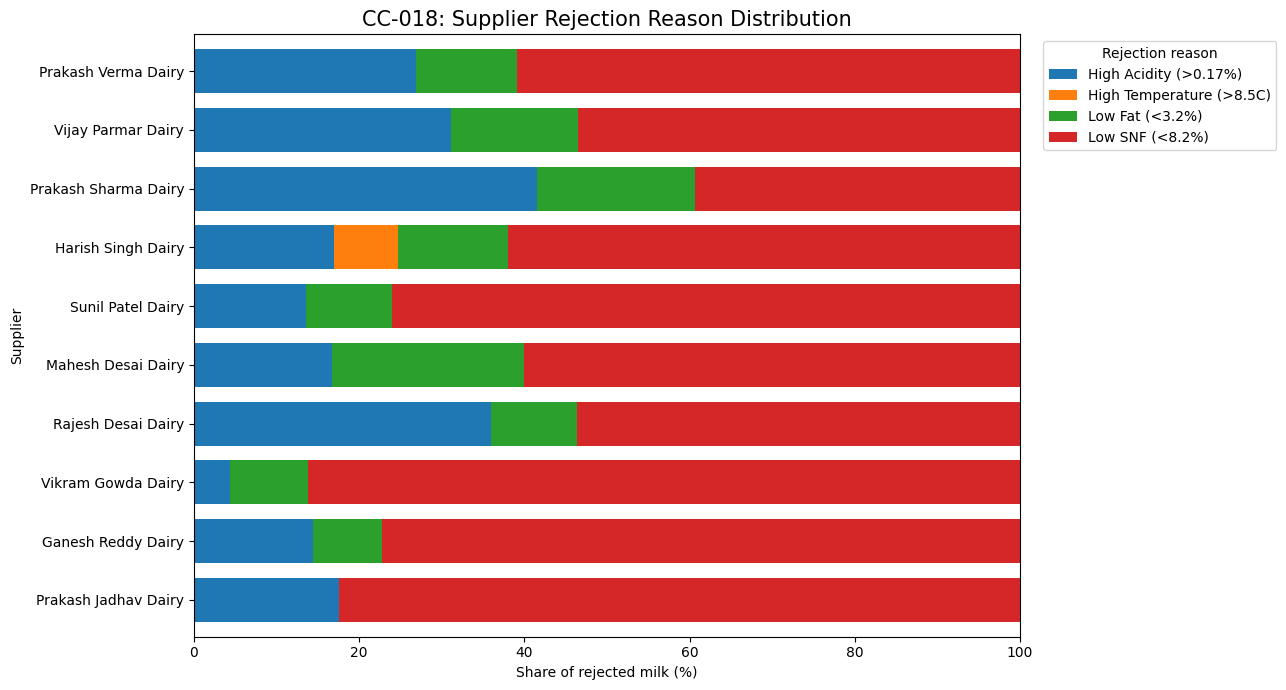

In [ ]:
import matplotlib.pyplot as plt

reason_cols = [
    'High Acidity (>0.17%)',
    'High Temperature (>8.5C)',
    'Low Fat (<3.2%)',
    'Low SNF (<8.2%)'
]

plot_df = cc018_supplier_reason_pct.set_index('supplier_name')[reason_cols]

ax = plot_df.plot(
    kind='barh',
    stacked=True,
    figsize=(13, 7),
    width=0.75
)

ax.set_title(
    'CC-018: Supplier Rejection Reason Distribution',
    fontsize=15
)
ax.set_xlabel('Share of rejected milk (%)')
ax.set_ylabel('Supplier')
ax.set_xlim(0, 100)
ax.legend(
    title='Rejection reason',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

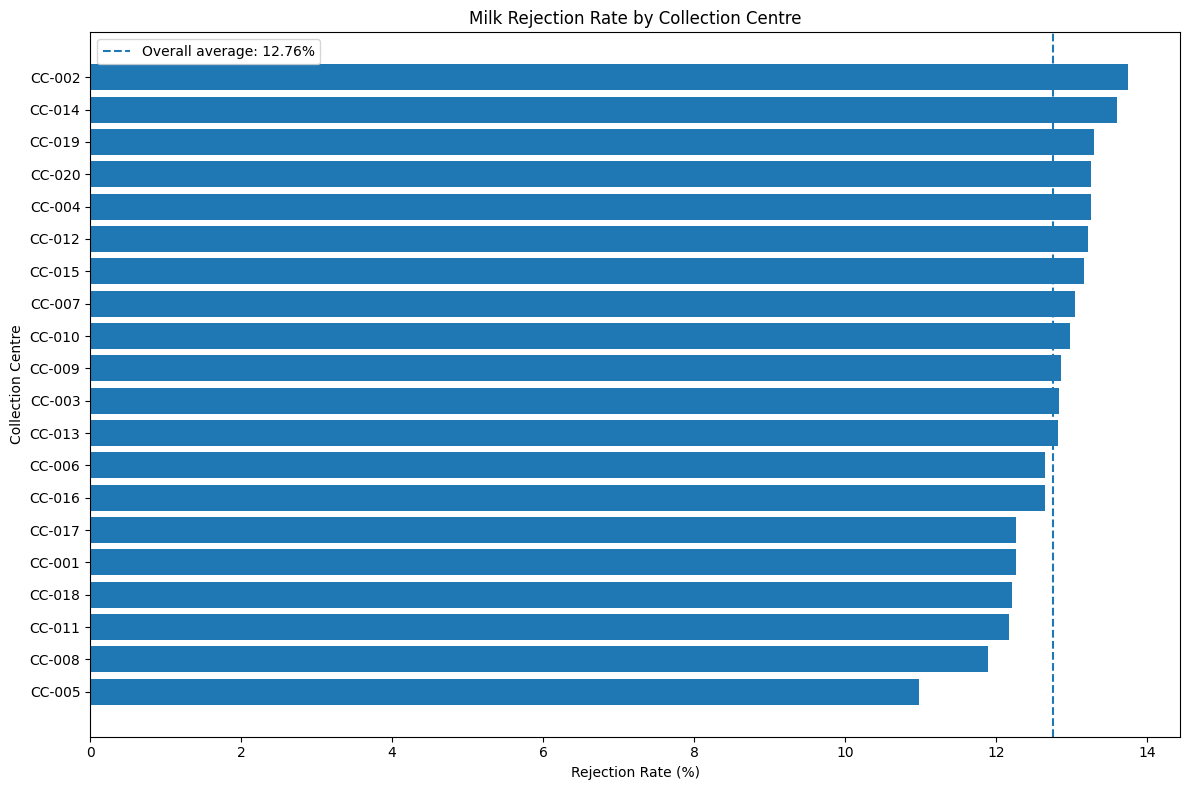

In [ ]:
import matplotlib.pyplot as plt

plot_df = center_summary.sort_values(
    'rejection_rate',
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    plot_df['collection_centre_id'],
    plot_df['rejection_rate']
)

plt.axvline(
    overall_rejection_rate,
    linestyle='--',
    label=f'Overall average: {overall_rejection_rate:.2f}%'
)

plt.title('Milk Rejection Rate by Collection Centre')
plt.xlabel('Rejection Rate (%)')
plt.ylabel('Collection Centre')
plt.legend()
plt.tight_layout()
plt.show()

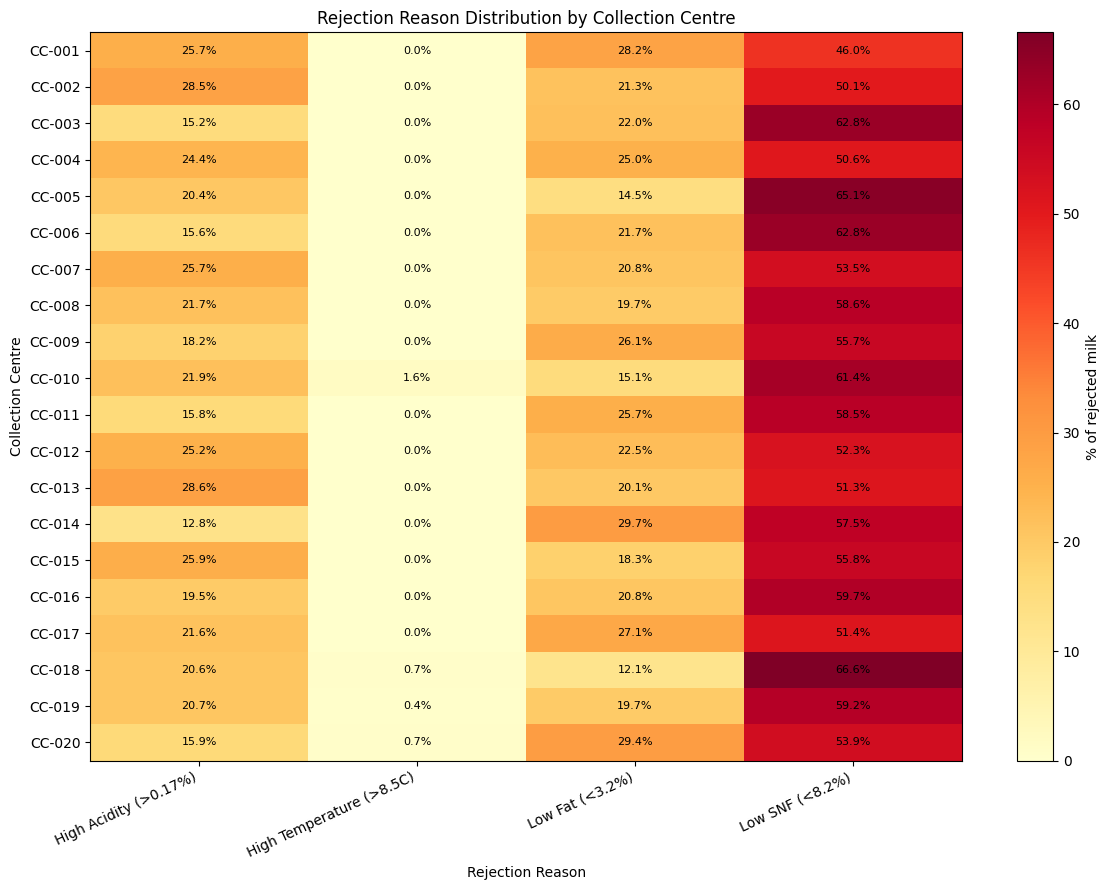

In [ ]:
import matplotlib.pyplot as plt

plot_df = center_reason_percentage.sort_index()

plt.figure(figsize=(12, 9))

plt.imshow(
    plot_df.values,
    aspect='auto',
    cmap='YlOrRd'
)

plt.xticks(
    range(len(plot_df.columns)),
    plot_df.columns,
    rotation=25,
    ha='right'
)

plt.yticks(
    range(len(plot_df.index)),
    plot_df.index
)

plt.colorbar(label='% of rejected milk')
plt.title('Rejection Reason Distribution by Collection Centre')
plt.xlabel('Rejection Reason')
plt.ylabel('Collection Centre')

for i in range(len(plot_df.index)):
    for j in range(len(plot_df.columns)):
        plt.text(
            j, i,
            f'{plot_df.iloc[i, j]:.1f}%',
            ha='center',
            va='center',
            fontsize=8
        )

plt.tight_layout()
plt.show()

/tmp/ipykernel_3295/443947861.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  monthly_rejection = monthly_rejection.groupby('month').apply(


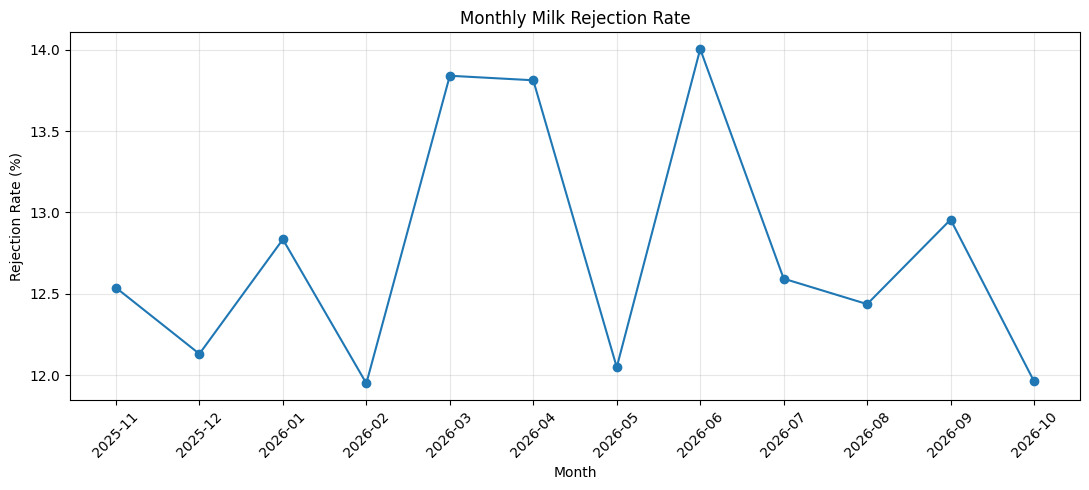

In [ ]:
monthly_rejection = procurement_df.copy()

monthly_rejection['month'] = (
    monthly_rejection['procurement_timestamp_clean']
    .dt.to_period('M')
)

monthly_rejection = monthly_rejection.groupby('month').apply(
    lambda x: (
        x.loc[x['acceptance_status'] == 'Rejected', 'quantity_litres'].sum()
        / x['quantity_litres'].sum() * 100
    )
).reset_index(name='rejection_rate')

monthly_rejection['month'] = (
    monthly_rejection['month'].astype(str)
)

plt.figure(figsize=(11, 5))

plt.plot(
    monthly_rejection['month'],
    monthly_rejection['rejection_rate'],
    marker='o'
)

plt.title('Monthly Milk Rejection Rate')
plt.xlabel('Month')
plt.ylabel('Rejection Rate (%)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


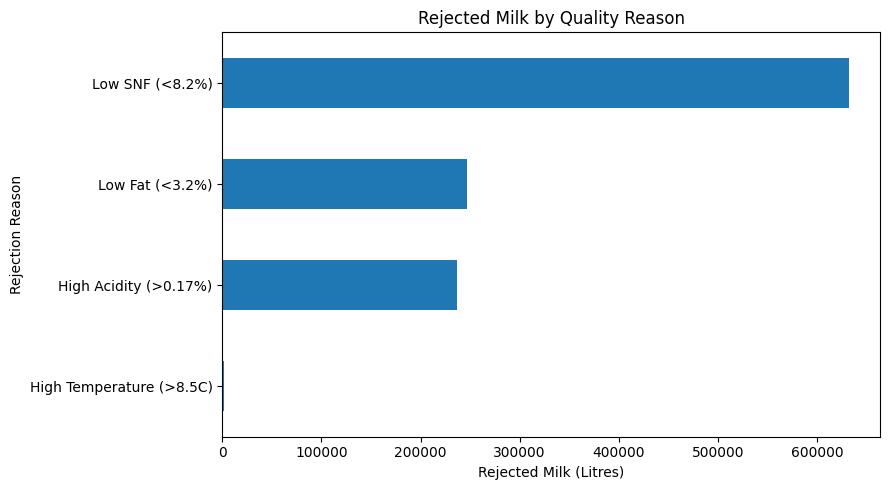

In [ ]:
reason_loss = center_reasons_df[
    center_reasons_df['acceptance_status'] == 'Rejected'
].groupby('rejection_reason')['quantity_litres'].sum().sort_values()

reason_loss.plot(
    kind='barh',
    figsize=(9, 5),
    title='Rejected Milk by Quality Reason'
)

plt.xlabel('Rejected Milk (Litres)')
plt.ylabel('Rejection Reason')
plt.tight_layout()
plt.show()

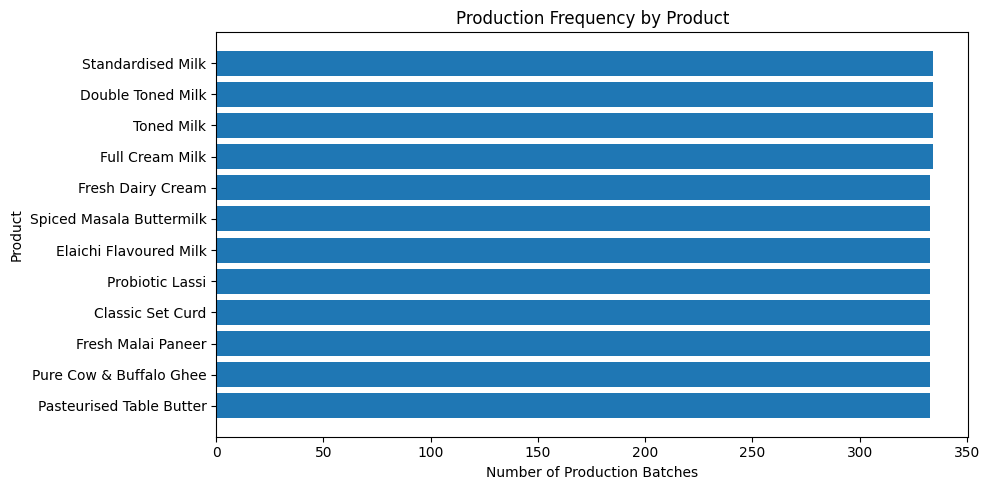

In [ ]:
production_frequency = production_outputs_df[
    production_outputs_df['output_classification'] == 'Primary product'
].groupby('product_id').agg(
    production_batches=('production_id', 'nunique')
).reset_index()

production_frequency = production_frequency.merge(
    products_df[['product_id', 'product_name']],
    on='product_id',
    how='left'
).sort_values('production_batches')

plt.figure(figsize=(10, 5))

plt.barh(
    production_frequency['product_name'],
    production_frequency['production_batches']
)

plt.title('Production Frequency by Product')
plt.xlabel('Number of Production Batches')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

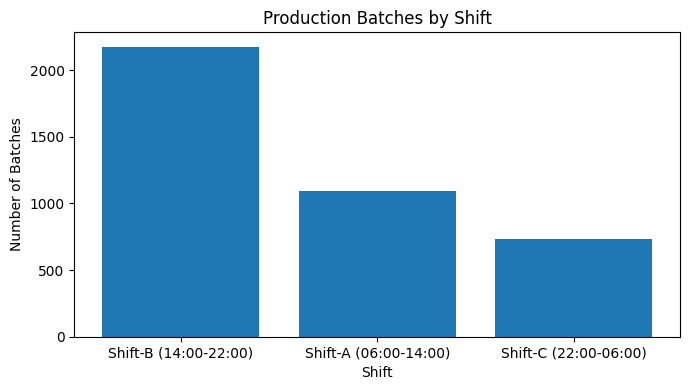

In [ ]:
shift_counts = production_batches_df['shift'].value_counts()

plt.figure(figsize=(7, 4))

plt.bar(shift_counts.index, shift_counts.values)

plt.title('Production Batches by Shift')
plt.xlabel('Shift')
plt.ylabel('Number of Batches')

plt.tight_layout()
plt.show()

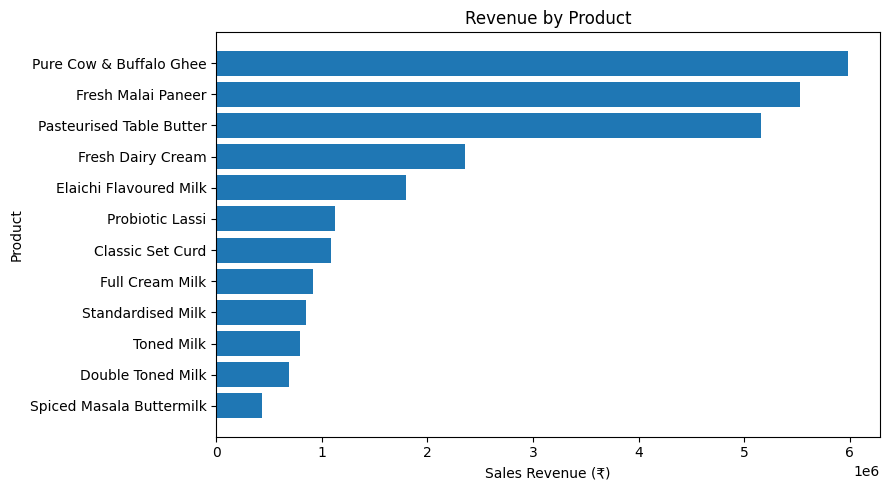

In [ ]:
product_sales = sales_order_lines_df.groupby(
    'product_id'
)['calculated_line_total'].sum().reset_index()

product_sales = product_sales.merge(
    products_df[['product_id', 'product_name']],
    on='product_id',
    how='left'
).sort_values('calculated_line_total')

plt.figure(figsize=(9, 5))

plt.barh(
    product_sales['product_name'],
    product_sales['calculated_line_total']
)

plt.title('Revenue by Product')
plt.xlabel('Sales Revenue (₹)')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

In [ ]:
& "C:\Program Files\PostgreSQL\18\bin\psql.exe" -U postgres -d dairychain

SyntaxError: invalid syntax (2992784812.py, line 1)